In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
import os

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def load_pf_data(protein, model_name, ensemble_dir="BIOEMU_DATA", exp_dir="EXP_DATA/PF_Nguyen_2018"):
    exp = pd.read_csv(f"../../{exp_dir}/{protein}.csv")
    residues = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/exp_residues.txt")
    try:
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_rew_lnPF.txt"))
    except:
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/rew_lnPF.txt"))
    priorPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/prior_lnPF.txt"))
    try:
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_stats_df.csv")
    except:
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/stats_df.csv")
    try:
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_reweighting_chi2_phi_theta.txt")
    except:
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/reweighting_chi2_phi_theta.txt")
    chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]
    idxs = [list(exp["Model_residue"]).index(ele) for ele in residues]
    return exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs


# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def calc_ccc(x, y):
    x = np.asarray(x)
    y = np.asarray(y)

    mx = np.mean(x)
    my = np.mean(y)
    vx = np.var(x, ddof=0)
    vy = np.var(y, ddof=0)
    sxy = np.cov(x, y, ddof=0)[0, 1]

    return 2 * sxy / (vx + vy + (mx - my) ** 2)



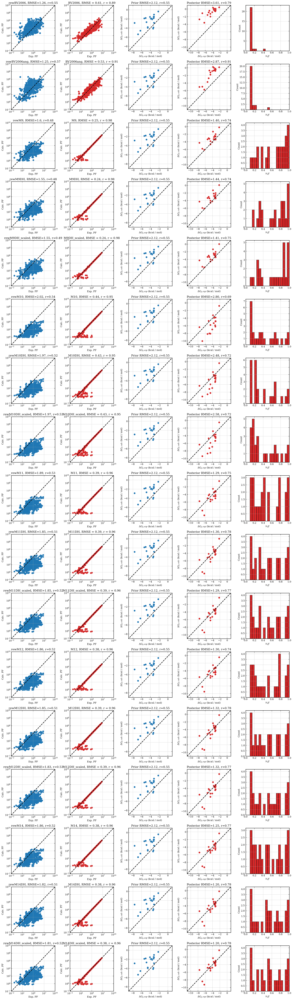

In [2]:



models = ['rewBV2006', 'rewBV2006ang', 
          'rewM9', 'rewM9DH', 'rewM9DH_scaled', 
          'rewM10', 'rewM10DH', 'rewM10DH_scaled', 
          'rewM11', 'rewM11DH', 'rewM11DH_scaled', 
          'rewM12', 'rewM12DH', 'rewM12DH_scaled',
          'rewM14', 'rewM14DH', 'rewM14DH_scaled'] 

proteins = ['ACBP', 'ACP', 'alpha3D', 'CLN025', 'GB3', 'HP36', 'Im7', 'NuG2', 'Ubiquitin',
            'EEHEE_rd4_0642-6xHis', 'EEHEE_rd4_0642-No-His',
            'EEHEE_rd4_0871-6xHis', 'EEHEE_rd4_0871-No-His',
            'EEHEE_rd4_0871_K31L_E36V-No-His', 'EHEE_rd2_0005-6xHis',
            'HEEH_rd4_0097-6xHis', 'HHH_rd1_0012-6xHis', 'HHH_rd3_0062-6xHis',
            'HHH_rd4_0518-6xHis', 'HHH_rd4_0518-No-His',
            'HHH_rd4_0518_R35D_G45L-No-His', 'HHH_rd4_0557-6xHis',
            'LysM_0873-No-His', 'LysM_1380-No-His', 'LysM_3314-No-His']

exp_dG_all = []
for protein in proteins:
    if os.path.exists(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat'):
        dg = np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat')[0]
        exp_dG_all.append(dg)
    else:
        exp_dG_all.append(np.nan)

all_expPF = []
# all experimental data
for i, protein in enumerate(proteins):
    exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name='rewBV2006')
    expPF = np.array(exp["PF"][idxs])
    all_expPF.append(expPF) 
all_expPF = np.concatenate([x for x in all_expPF if len(x) > 0])

fig, axes = plt.subplots(nrows=len(models), ncols=5, figsize=(17, 3.5 * len(models)))

for i, model in enumerate(models):

    # load data
    data = np.load(f'{model}_data_dict.npy',allow_pickle=True).item()
    all_calcPF = data['rew PF']
    neffs = data['neff']
    dGcalc = data['dG post']
    dGpcalc = data['dGp post']

    all_calcPF_prior = data['prior PF']
    neffs = data['neff']
    dGcalc_prior = data['dG prior']
    dGpcalc_prior = data['dGp prior']

    all_calcPF = np.concatenate([x for x in all_calcPF if len(x) > 0])
    all_calcPF_prior = np.concatenate([x for x in all_calcPF_prior if len(x) > 0])
    #assert all_calcPF.shape[0]==all_expPF.shape[0]

    # --- Plot 1: PF calculated vs experiments (prior) ---
    ax = axes[i, 0]
    ax.scatter(all_expPF, all_calcPF_prior, c="tab:blue")
    ax.plot([1e-4, 1e10], [1e-4, 1e10], "k--")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(1e-2, 1e10); ax.set_ylim(1e-2, 1e10)
    ax.set_xlabel("Exp. PF"); ax.set_ylabel("Calc. PF")

    x, y = np.log10(all_expPF), np.log10(all_calcPF_prior)
    rmse = np.round(RMSE(x, y), 2)
    r = np.round(scipy.stats.pearsonr(x, y)[0], 2)
    ax.set_title(f"{model}, RMSE={rmse}, r={r}")

    # --- Plot 2: PF calculated vs experiments ---
    ax = axes[i, 1]
    ax.scatter(all_expPF, all_calcPF, c="tab:red")
    ax.plot([1e-4, 1e10], [1e-4, 1e10], "k--")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(1e-2, 1e10); ax.set_ylim(1e-2, 1e10)
    ax.set_xlabel("Exp. PF"); ax.set_ylabel("Calc. PF")

    x, y = np.log10(all_expPF), np.log10(all_calcPF)
    rmse = np.round(RMSE(x, y), 2)
    r = np.round(scipy.stats.pearsonr(x, y)[0], 2)
    ax.set_title(f"{model[3:]}, RMSE = {rmse}, r = {r}")

    # --- Plot 3: dG calc vs dG HDX prior ---
    ax = axes[i, 2]

    valid = ~np.isnan(exp_dG_all) 
    exp_dG = np.array(exp_dG_all)[valid]
    dGpcalc_prior = np.array(dGpcalc_prior)[valid]
    dGpcalc = np.array(dGpcalc)[valid]

    rmse = np.round(RMSE(exp_dG, dGpcalc_prior), 2)
    r = np.round(scipy.stats.pearsonr(exp_dG, dGpcalc_prior)[0], 2)
    ax.scatter(exp_dG, dGpcalc_prior, c="tab:blue")
    ax.set_title('Prior RMSE={:.2f}, r={:.2f}'.format(rmse, r))

    ax.set_xlabel('ΔG$_f,exp$ (kcal / mol)')
    ax.set_ylabel('ΔG$_f,calc$ (kcal / mol)')
    ax.set_ylim(-9, 1)
    ax.set_xlim(-9, 1)
    ax.plot([-12, 4], [-12, 4], "k--")

    # --- Plot 4: dGp calc vs dG HDX---
    ax = axes[i, 3]

    rmse = np.round(RMSE(exp_dG, dGpcalc), 2)
    r = np.round(scipy.stats.pearsonr(exp_dG, dGpcalc)[0], 2)
    ax.scatter(exp_dG, dGpcalc, c="tab:red")
    ax.set_title('Posterior RMSE={:.2f}, r={:.2f}'.format(rmse, r))

    ax.set_xlabel('ΔG$_f,exp$ (kcal / mol)')
    ax.set_ylabel('ΔG$_f,calc$ (kcal / mol)')
    ax.set_ylim(-11, 1)
    ax.set_xlim(-11, 1)
    ax.plot([-12, 4], [-12, 4], "k--")
    

    # --- Plot 5: neffs histogram ---
    ax = axes[i, 4]
    bins = np.linspace(0, 1, 21)  # 20 bins, 21 edges
    ax.hist(neffs, bins=bins, color="tab:red", edgecolor='black')
    ax.set_xlim(0,1)
    ax.set_xlabel('$N_eff$')
    ax.set_ylabel('Count')


plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(f"model_comparison.png", dpi=200, bbox_inches="tight")


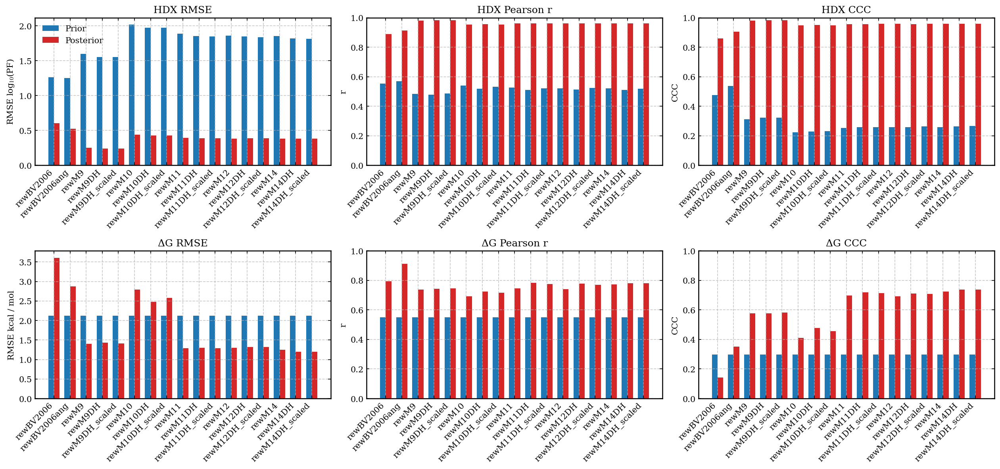

In [3]:
# summary barplot of model performances


models = ['rewBV2006', 'rewBV2006ang', 
          'rewM9', 'rewM9DH', 'rewM9DH_scaled', 
          'rewM10', 'rewM10DH', 'rewM10DH_scaled', 
          'rewM11', 'rewM11DH', 'rewM11DH_scaled', 
          'rewM12', 'rewM12DH', 'rewM12DH_scaled',
          'rewM14', 'rewM14DH', 'rewM14DH_scaled'] 

proteins = ['ACBP', 'ACP', 'alpha3D', 'CLN025', 'GB3', 'HP36', 'Im7', 'NuG2', 'Ubiquitin',
            'EEHEE_rd4_0642-6xHis', 'EEHEE_rd4_0642-No-His',
            'EEHEE_rd4_0871-6xHis', 'EEHEE_rd4_0871-No-His',
            'EEHEE_rd4_0871_K31L_E36V-No-His', 'EHEE_rd2_0005-6xHis',
            'HEEH_rd4_0097-6xHis', 'HHH_rd1_0012-6xHis', 'HHH_rd3_0062-6xHis',
            'HHH_rd4_0518-6xHis', 'HHH_rd4_0518-No-His',
            'HHH_rd4_0518_R35D_G45L-No-His', 'HHH_rd4_0557-6xHis',
            'LysM_0873-No-His', 'LysM_1380-No-His', 'LysM_3314-No-His'] 

# -----------------------------
# Storage for metrics
# -----------------------------
rmse_HDX_prior, rmse_HDX_post = [], []
r_HDX_prior, r_HDX_post = [], []
ccc_HDX_prior, ccc_HDX_post = [], []

rmse_dG_prior, rmse_dG_post = [], []
r_dG_prior, r_dG_post = [], []
ccc_dG_prior, ccc_dG_post = [], []


exp_dG_all = []
for protein in proteins:
    if os.path.exists(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat'):
        dg = np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat')[0]
        exp_dG_all.append(dg)
    else:
        dg = np.nan
        exp_dG_all.append(dg)

all_expPF = []
# all experimental data
for i, protein in enumerate(proteins):
    exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name='rewBV2006')
    expPF = np.array(exp["PF"][idxs])
    all_expPF.append(expPF) 
all_expPF = np.concatenate([x for x in all_expPF if len(x) > 0])

valid = ~np.isnan(exp_dG_all)
exp_dG = np.array(exp_dG_all)[valid]



########################
### Loop over models  ###
########################

for model in models:

    # -----------------------------
    # Load model data
    # -----------------------------
    data = np.load(
        f'../Folding_landscapes/{model}_data_dict.npy',
        allow_pickle=True
    ).item()

    # PF data
    all_calcPF = np.concatenate([x for x in data['rew PF'] if len(x) > 0])
    all_calcPF_prior = np.concatenate([x for x in data['prior PF'] if len(x) > 0])

    dGpcalc = np.array(data['dGp post'])[valid]
    dGpcalc_prior = np.array(data['dGp prior'])[valid]


    # -----------------------------
    # Sanity checks
    # -----------------------------
    if len(all_calcPF) != len(all_expPF):
        raise ValueError(
            f"{model}: posterior PF length mismatch: "
            f"calc={len(all_calcPF)}, exp={len(all_expPF)}"
        )

    if len(all_calcPF_prior) != len(all_expPF):
        raise ValueError(
            f"{model}: prior PF length mismatch: "
            f"calc={len(all_calcPF_prior)}, exp={len(all_expPF)}"
        )

    if len(dGpcalc) != len(exp_dG):
        raise ValueError(
            f"{model}: posterior dG length mismatch: "
            f"calc={len(dGpcalc)}, exp={len(exp_dG)}"
        )

    if len(dGpcalc_prior) != len(exp_dG):
        raise ValueError(
            f"{model}: prior dG length mismatch: "
            f"calc={len(dGpcalc_prior)}, exp={len(exp_dG)}"
        )

    # -----------------------------
    # HDX PF metrics
    # -----------------------------
    x_exp = np.log10(all_expPF)

    y_prior = np.log10(all_calcPF_prior)
    y_post = np.log10(all_calcPF)

    rmse_HDX_prior.append(RMSE(x_exp, y_prior))
    rmse_HDX_post.append(RMSE(x_exp, y_post))

    r_HDX_prior.append(scipy.stats.pearsonr(x_exp, y_prior)[0])
    r_HDX_post.append(scipy.stats.pearsonr(x_exp, y_post)[0])

    ccc_HDX_prior.append(calc_ccc(x_exp, y_prior))
    ccc_HDX_post.append(calc_ccc(x_exp, y_post))

    # -----------------------------
    # ΔG metrics
    # -----------------------------
    rmse_dG_prior.append(RMSE(exp_dG, dGpcalc_prior))
    rmse_dG_post.append(RMSE(exp_dG, dGpcalc))

    r_dG_prior.append(scipy.stats.pearsonr(exp_dG, dGpcalc_prior)[0])
    r_dG_post.append(scipy.stats.pearsonr(exp_dG, dGpcalc)[0])

    ccc_dG_prior.append(calc_ccc(exp_dG, dGpcalc_prior))
    ccc_dG_post.append(calc_ccc(exp_dG, dGpcalc))


# -----------------------------
# Build 6-panel summary figure
# -----------------------------
fig, axes = plt.subplots(2, 3, figsize=(17, 8))

bar_width = 0.35
x = np.arange(len(models))


# --- Panel 1: RMSE HDX ---
ax = axes[0, 0]
ax.bar(x - bar_width / 2, rmse_HDX_prior, bar_width, label='Prior', color='tab:blue')
ax.bar(x + bar_width / 2, rmse_HDX_post,  bar_width, label='Posterior', color='tab:red')
ax.set_title("HDX RMSE")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right')
ax.set_ylabel("RMSE log$_{10}$(PF)")
ax.legend(loc='upper left')


# --- Panel 2: Pearson r HDX ---
ax = axes[0, 1]
ax.bar(x - bar_width / 2, r_HDX_prior, bar_width, label='Prior', color='tab:blue')
ax.bar(x + bar_width / 2, r_HDX_post,  bar_width, label='Posterior', color='tab:red')
ax.set_title("HDX Pearson r")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right')
ax.set_ylabel("r")
ax.set_ylim(0, 1)


# --- Panel 3: CCC HDX ---
ax = axes[0, 2]
ax.bar(x - bar_width / 2, ccc_HDX_prior, bar_width, label='Prior', color='tab:blue')
ax.bar(x + bar_width / 2, ccc_HDX_post,  bar_width, label='Posterior', color='tab:red')
ax.set_title("HDX CCC")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right')
ax.set_ylabel("CCC")
ax.set_ylim(0, 1)


# --- Panel 4: RMSE ΔG ---
ax = axes[1, 0]
ax.bar(x - bar_width / 2, rmse_dG_prior, bar_width, label='Prior', color='tab:blue')
ax.bar(x + bar_width / 2, rmse_dG_post,  bar_width, label='Posterior', color='tab:red')
ax.set_title("ΔG RMSE")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right')
ax.set_ylabel("RMSE kcal / mol")


# --- Panel 5: Pearson r ΔG ---
ax = axes[1, 1]
ax.bar(x - bar_width / 2, r_dG_prior, bar_width, label='Prior', color='tab:blue')
ax.bar(x + bar_width / 2, r_dG_post,  bar_width, label='Posterior', color='tab:red')
ax.set_title("ΔG Pearson r")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right')
ax.set_ylabel("r")
ax.set_ylim(0, 1)


# --- Panel 6: CCC ΔG ---
ax = axes[1, 2]
ax.bar(x - bar_width / 2, ccc_dG_prior, bar_width, label='Prior', color='tab:blue')
ax.bar(x + bar_width / 2, ccc_dG_post,  bar_width, label='Posterior', color='tab:red')
ax.set_title("ΔG CCC")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right')
ax.set_ylabel("CCC")
ax.set_ylim(0, 1)


plt.tight_layout()
plt.savefig("models_barplot_summary.png", dpi=200, bbox_inches="tight")
plt.show()

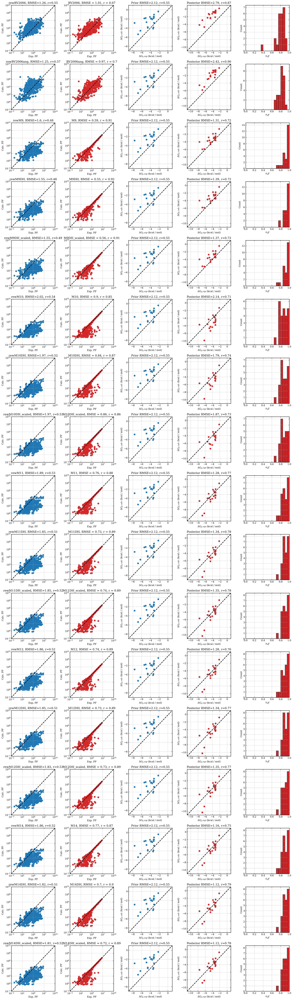

In [4]:



models = ['rewBV2006', 'rewBV2006ang', 
          'rewM9', 'rewM9DH', 'rewM9DH_scaled', 
          'rewM10', 'rewM10DH', 'rewM10DH_scaled', 
          'rewM11', 'rewM11DH', 'rewM11DH_scaled', 
          'rewM12', 'rewM12DH', 'rewM12DH_scaled',
          'rewM14', 'rewM14DH', 'rewM14DH_scaled'] 

proteins = ['ACBP', 'ACP', 'alpha3D', 'CLN025', 'GB3', 'HP36', 'Im7', 'NuG2', 'Ubiquitin',
            'EEHEE_rd4_0642-6xHis', 'EEHEE_rd4_0642-No-His',
            'EEHEE_rd4_0871-6xHis', 'EEHEE_rd4_0871-No-His',
            'EEHEE_rd4_0871_K31L_E36V-No-His', 'EHEE_rd2_0005-6xHis',
            'HEEH_rd4_0097-6xHis', 'HHH_rd1_0012-6xHis', 'HHH_rd3_0062-6xHis',
            'HHH_rd4_0518-6xHis', 'HHH_rd4_0518-No-His',
            'HHH_rd4_0518_R35D_G45L-No-His', 'HHH_rd4_0557-6xHis',
            'LysM_0873-No-His', 'LysM_1380-No-His', 'LysM_3314-No-His']

exp_dG_all = []
for protein in proteins:
    if os.path.exists(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat'):
        dg = np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat')[0]
        exp_dG_all.append(dg)
    else:
        exp_dG_all.append(np.nan)

all_expPF = []
# all experimental data
for i, protein in enumerate(proteins):
    exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name='rewBV2006')
    expPF = np.array(exp["PF"][idxs])
    all_expPF.append(expPF) 
all_expPF = np.concatenate([x for x in all_expPF if len(x) > 0])

fig, axes = plt.subplots(nrows=len(models), ncols=5, figsize=(17, 3.5 * len(models)))

for i, model in enumerate(models):

    # load data
    data = np.load(f'{model}_data_dict_elbow_posterior.npy',allow_pickle=True).item()
    all_calcPF = data['rew PF']
    neffs = data['neff']
    dGcalc = data['dG post']
    dGpcalc = data['dGp post']

    all_calcPF_prior = data['prior PF']
    neffs = data['neff']
    dGcalc_prior = data['dG prior']
    dGpcalc_prior = data['dGp prior']

    all_calcPF = np.concatenate([x for x in all_calcPF if len(x) > 0])
    all_calcPF_prior = np.concatenate([x for x in all_calcPF_prior if len(x) > 0])
    #assert all_calcPF.shape[0]==all_expPF.shape[0]

    # --- Plot 1: PF calculated vs experiments (prior) ---
    ax = axes[i, 0]
    ax.scatter(all_expPF, all_calcPF_prior, c="tab:blue")
    ax.plot([1e-4, 1e10], [1e-4, 1e10], "k--")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(1e-2, 1e10); ax.set_ylim(1e-2, 1e10)
    ax.set_xlabel("Exp. PF"); ax.set_ylabel("Calc. PF")

    x, y = np.log10(all_expPF), np.log10(all_calcPF_prior)
    rmse = np.round(RMSE(x, y), 2)
    r = np.round(scipy.stats.pearsonr(x, y)[0], 2)
    ax.set_title(f"{model}, RMSE={rmse}, r={r}")

    # --- Plot 2: PF calculated vs experiments ---
    ax = axes[i, 1]
    ax.scatter(all_expPF, all_calcPF, c="tab:red")
    ax.plot([1e-4, 1e10], [1e-4, 1e10], "k--")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(1e-2, 1e10); ax.set_ylim(1e-2, 1e10)
    ax.set_xlabel("Exp. PF"); ax.set_ylabel("Calc. PF")

    x, y = np.log10(all_expPF), np.log10(all_calcPF)
    rmse = np.round(RMSE(x, y), 2)
    r = np.round(scipy.stats.pearsonr(x, y)[0], 2)
    ax.set_title(f"{model[3:]}, RMSE = {rmse}, r = {r}")

    # --- Plot 3: dG calc vs dG HDX prior ---
    ax = axes[i, 2]

    valid = ~np.isnan(exp_dG_all) 
    exp_dG = np.array(exp_dG_all)[valid]
    dGpcalc_prior = np.array(dGpcalc_prior)[valid]
    dGpcalc = np.array(dGpcalc)[valid]

    rmse = np.round(RMSE(exp_dG, dGpcalc_prior), 2)
    r = np.round(scipy.stats.pearsonr(exp_dG, dGpcalc_prior)[0], 2)
    ax.scatter(exp_dG, dGpcalc_prior, c="tab:blue")
    ax.set_title('Prior RMSE={:.2f}, r={:.2f}'.format(rmse, r))

    ax.set_xlabel('ΔG$_f,exp$ (kcal / mol)')
    ax.set_ylabel('ΔG$_f,calc$ (kcal / mol)')
    ax.set_ylim(-9, 1)
    ax.set_xlim(-9, 1)
    ax.plot([-12, 4], [-12, 4], "k--")

    # --- Plot 4: dGp calc vs dG HDX---
    ax = axes[i, 3]

    rmse = np.round(RMSE(exp_dG, dGpcalc), 2)
    r = np.round(scipy.stats.pearsonr(exp_dG, dGpcalc)[0], 2)
    ax.scatter(exp_dG, dGpcalc, c="tab:red")
    ax.set_title('Posterior RMSE={:.2f}, r={:.2f}'.format(rmse, r))

    ax.set_xlabel('ΔG$_f,exp$ (kcal / mol)')
    ax.set_ylabel('ΔG$_f,calc$ (kcal / mol)')
    ax.set_ylim(-11, 1)
    ax.set_xlim(-11, 1)
    ax.plot([-12, 4], [-12, 4], "k--")
    

    # --- Plot 5: neffs histogram ---
    ax = axes[i, 4]
    bins = np.linspace(0, 1, 21)  # 20 bins, 21 edges
    ax.hist(neffs, bins=bins, color="tab:red", edgecolor='black')
    ax.set_xlim(0,1)
    ax.set_xlabel('$N_eff$')
    ax.set_ylabel('Count')


plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig(f"model_comparison_elbow_posterior.png", dpi=200, bbox_inches="tight")


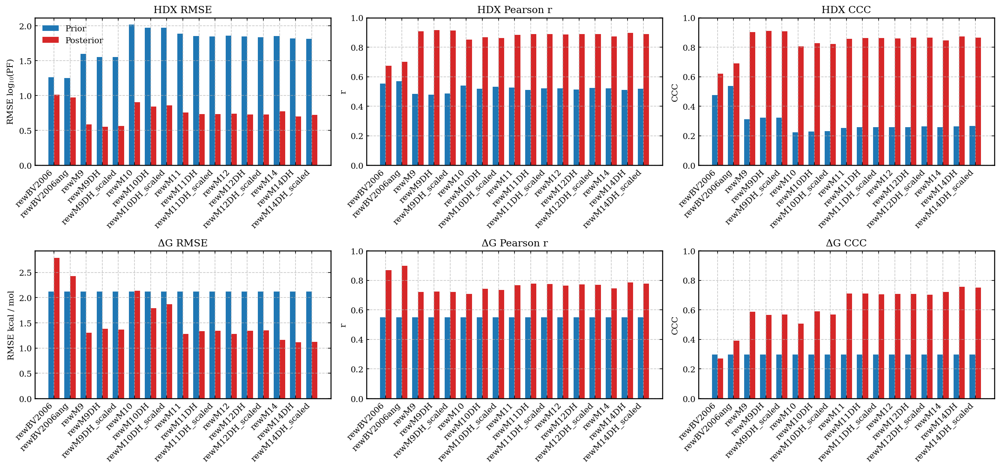

In [5]:
# summary barplot of model performances


models = ['rewBV2006', 'rewBV2006ang', 
          'rewM9', 'rewM9DH', 'rewM9DH_scaled', 
          'rewM10', 'rewM10DH', 'rewM10DH_scaled', 
          'rewM11', 'rewM11DH', 'rewM11DH_scaled', 
          'rewM12', 'rewM12DH', 'rewM12DH_scaled',
          'rewM14', 'rewM14DH', 'rewM14DH_scaled'] 

proteins = ['ACBP', 'ACP', 'alpha3D', 'CLN025', 'GB3', 'HP36', 'Im7', 'NuG2', 'Ubiquitin',
            'EEHEE_rd4_0642-6xHis', 'EEHEE_rd4_0642-No-His',
            'EEHEE_rd4_0871-6xHis', 'EEHEE_rd4_0871-No-His',
            'EEHEE_rd4_0871_K31L_E36V-No-His', 'EHEE_rd2_0005-6xHis',
            'HEEH_rd4_0097-6xHis', 'HHH_rd1_0012-6xHis', 'HHH_rd3_0062-6xHis',
            'HHH_rd4_0518-6xHis', 'HHH_rd4_0518-No-His',
            'HHH_rd4_0518_R35D_G45L-No-His', 'HHH_rd4_0557-6xHis',
            'LysM_0873-No-His', 'LysM_1380-No-His', 'LysM_3314-No-His'] 

# -----------------------------
# Storage for metrics
# -----------------------------
rmse_HDX_prior, rmse_HDX_post = [], []
r_HDX_prior, r_HDX_post = [], []
ccc_HDX_prior, ccc_HDX_post = [], []

rmse_dG_prior, rmse_dG_post = [], []
r_dG_prior, r_dG_post = [], []
ccc_dG_prior, ccc_dG_post = [], []


exp_dG_all = []
for protein in proteins:
    if os.path.exists(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat'):
        dg = np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat')[0]
        exp_dG_all.append(dg)
    else:
        dg = np.nan
        exp_dG_all.append(dg)

all_expPF = []
# all experimental data
for i, protein in enumerate(proteins):
    exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name='rewBV2006')
    expPF = np.array(exp["PF"][idxs])
    all_expPF.append(expPF) 
all_expPF = np.concatenate([x for x in all_expPF if len(x) > 0])

valid = ~np.isnan(exp_dG_all)
exp_dG = np.array(exp_dG_all)[valid]



########################
### Loop over models  ###
########################

for model in models:

    # -----------------------------
    # Load model data
    # -----------------------------
    data = np.load(
        f'../Folding_landscapes/{model}_data_dict_elbow_posterior.npy',
        allow_pickle=True
    ).item()

    # PF data
    all_calcPF = np.concatenate([x for x in data['rew PF'] if len(x) > 0])
    all_calcPF_prior = np.concatenate([x for x in data['prior PF'] if len(x) > 0])

    dGpcalc = np.array(data['dGp post'])[valid]
    dGpcalc_prior = np.array(data['dGp prior'])[valid]


    # -----------------------------
    # Sanity checks
    # -----------------------------
    if len(all_calcPF) != len(all_expPF):
        raise ValueError(
            f"{model}: posterior PF length mismatch: "
            f"calc={len(all_calcPF)}, exp={len(all_expPF)}"
        )

    if len(all_calcPF_prior) != len(all_expPF):
        raise ValueError(
            f"{model}: prior PF length mismatch: "
            f"calc={len(all_calcPF_prior)}, exp={len(all_expPF)}"
        )

    if len(dGpcalc) != len(exp_dG):
        raise ValueError(
            f"{model}: posterior dG length mismatch: "
            f"calc={len(dGpcalc)}, exp={len(exp_dG)}"
        )

    if len(dGpcalc_prior) != len(exp_dG):
        raise ValueError(
            f"{model}: prior dG length mismatch: "
            f"calc={len(dGpcalc_prior)}, exp={len(exp_dG)}"
        )

    # -----------------------------
    # HDX PF metrics
    # -----------------------------
    x_exp = np.log10(all_expPF)

    y_prior = np.log10(all_calcPF_prior)
    y_post = np.log10(all_calcPF)

    rmse_HDX_prior.append(RMSE(x_exp, y_prior))
    rmse_HDX_post.append(RMSE(x_exp, y_post))

    r_HDX_prior.append(scipy.stats.pearsonr(x_exp, y_prior)[0])
    r_HDX_post.append(scipy.stats.pearsonr(x_exp, y_post)[0])

    ccc_HDX_prior.append(calc_ccc(x_exp, y_prior))
    ccc_HDX_post.append(calc_ccc(x_exp, y_post))

    # -----------------------------
    # ΔG metrics
    # -----------------------------
    rmse_dG_prior.append(RMSE(exp_dG, dGpcalc_prior))
    rmse_dG_post.append(RMSE(exp_dG, dGpcalc))

    r_dG_prior.append(scipy.stats.pearsonr(exp_dG, dGpcalc_prior)[0])
    r_dG_post.append(scipy.stats.pearsonr(exp_dG, dGpcalc)[0])

    ccc_dG_prior.append(calc_ccc(exp_dG, dGpcalc_prior))
    ccc_dG_post.append(calc_ccc(exp_dG, dGpcalc))


# -----------------------------
# Build 6-panel summary figure
# -----------------------------
fig, axes = plt.subplots(2, 3, figsize=(17, 8))

bar_width = 0.35
x = np.arange(len(models))


# --- Panel 1: RMSE HDX ---
ax = axes[0, 0]
ax.bar(x - bar_width / 2, rmse_HDX_prior, bar_width, label='Prior', color='tab:blue')
ax.bar(x + bar_width / 2, rmse_HDX_post,  bar_width, label='Posterior', color='tab:red')
ax.set_title("HDX RMSE")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right')
ax.set_ylabel("RMSE log$_{10}$(PF)")
ax.legend(loc='upper left')


# --- Panel 2: Pearson r HDX ---
ax = axes[0, 1]
ax.bar(x - bar_width / 2, r_HDX_prior, bar_width, label='Prior', color='tab:blue')
ax.bar(x + bar_width / 2, r_HDX_post,  bar_width, label='Posterior', color='tab:red')
ax.set_title("HDX Pearson r")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right')
ax.set_ylabel("r")
ax.set_ylim(0, 1)


# --- Panel 3: CCC HDX ---
ax = axes[0, 2]
ax.bar(x - bar_width / 2, ccc_HDX_prior, bar_width, label='Prior', color='tab:blue')
ax.bar(x + bar_width / 2, ccc_HDX_post,  bar_width, label='Posterior', color='tab:red')
ax.set_title("HDX CCC")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right')
ax.set_ylabel("CCC")
ax.set_ylim(0, 1)


# --- Panel 4: RMSE ΔG ---
ax = axes[1, 0]
ax.bar(x - bar_width / 2, rmse_dG_prior, bar_width, label='Prior', color='tab:blue')
ax.bar(x + bar_width / 2, rmse_dG_post,  bar_width, label='Posterior', color='tab:red')
ax.set_title("ΔG RMSE")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right')
ax.set_ylabel("RMSE kcal / mol")


# --- Panel 5: Pearson r ΔG ---
ax = axes[1, 1]
ax.bar(x - bar_width / 2, r_dG_prior, bar_width, label='Prior', color='tab:blue')
ax.bar(x + bar_width / 2, r_dG_post,  bar_width, label='Posterior', color='tab:red')
ax.set_title("ΔG Pearson r")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right')
ax.set_ylabel("r")
ax.set_ylim(0, 1)


# --- Panel 6: CCC ΔG ---
ax = axes[1, 2]
ax.bar(x - bar_width / 2, ccc_dG_prior, bar_width, label='Prior', color='tab:blue')
ax.bar(x + bar_width / 2, ccc_dG_post,  bar_width, label='Posterior', color='tab:red')
ax.set_title("ΔG CCC")
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right')
ax.set_ylabel("CCC")
ax.set_ylim(0, 1)


plt.tight_layout()
plt.savefig("models_barplot_summary_elbow_posterior.png", dpi=200, bbox_inches="tight")
plt.show()

In [6]:
## PLOTS FOR MAIN FIGURES ##   

Calc dG min/max: -3.588843560287568 0.44844921553637324
Calc dG min/max: -6.0957632310103 -0.19139225689065822
Calc dG min/max: -9.249983860639354 -0.20635265661592703


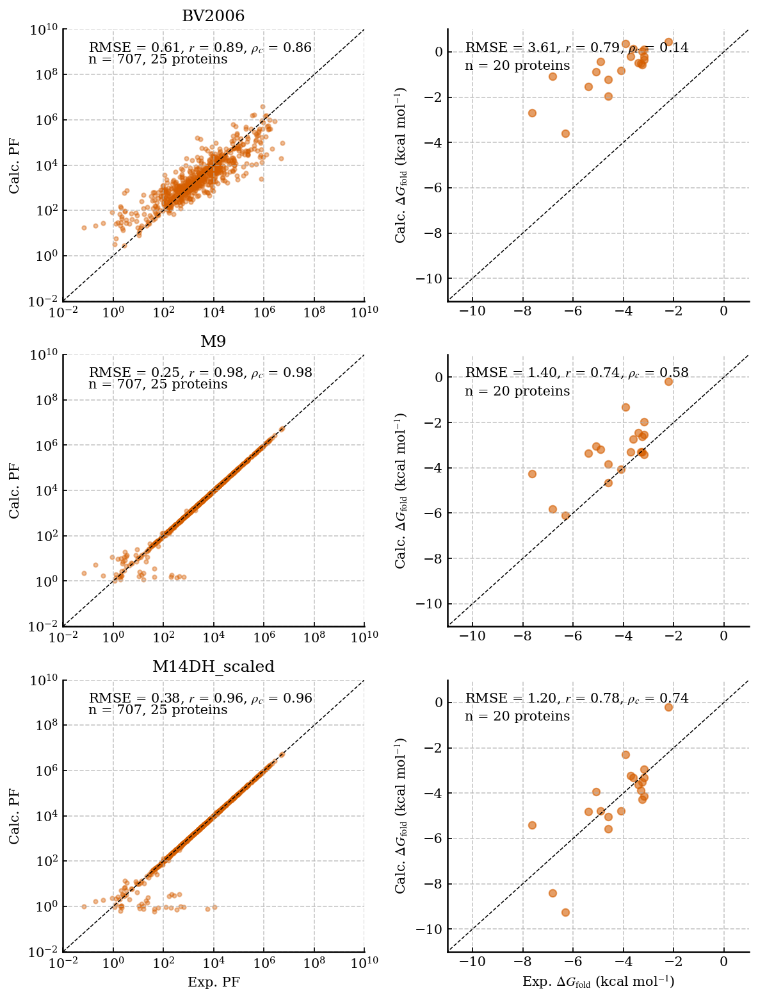

In [14]:
models = ['rewBV2006', 'rewM9', 'rewM14DH_scaled']
model_labels = ['BV2006', 'M9', 'M14DH_scaled']

proteins = ['ACBP', 'ACP', 'alpha3D', 'CLN025', 'GB3', 'HP36', 'Im7', 'NuG2', 'Ubiquitin',
            'EEHEE_rd4_0642-6xHis', 'EEHEE_rd4_0642-No-His',
            'EEHEE_rd4_0871-6xHis', 'EEHEE_rd4_0871-No-His',
            'EEHEE_rd4_0871_K31L_E36V-No-His', 'EHEE_rd2_0005-6xHis',
            'HEEH_rd4_0097-6xHis', 'HHH_rd1_0012-6xHis', 'HHH_rd3_0062-6xHis',
            'HHH_rd4_0518-6xHis', 'HHH_rd4_0518-No-His',
            'HHH_rd4_0518_R35D_G45L-No-His', 'HHH_rd4_0557-6xHis',
            'LysM_0873-No-His', 'LysM_1380-No-His', 'LysM_3314-No-His']

POSTERIOR_COLOR = "#D55E00"

# --------------------------------------------------
# Experimental dG
# --------------------------------------------------
exp_dG_all = []
for protein in proteins:
    if os.path.exists(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat'):
        exp_dG_all.append(np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat')[0])
    else:
        exp_dG_all.append(np.nan)
exp_dG_all = np.array(exp_dG_all)

# --------------------------------------------------
# Experimental PFs
# --------------------------------------------------
all_expPF = []
for protein in proteins:
    exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name='rewBV2006')
    expPF = np.array(exp["PF"][idxs])
    all_expPF.append(expPF)
all_expPF = np.concatenate([x for x in all_expPF if len(x) > 0])

# --------------------------------------------------
# Figure
# --------------------------------------------------
fig, axes = plt.subplots(3, 2, figsize=(8, 10.5))
identity_pf = np.logspace(-2, 10, 200)
identity_dG = np.linspace(-12, 2, 200)

for row, (model, model_label) in enumerate(zip(models, model_labels)):

    data = np.load(f'{model}_data_dict.npy', allow_pickle=True).item()
    all_calcPF = np.concatenate([x for x in data['rew PF'] if len(x) > 0])
    dGpcalc = np.array(data['dGp post'])

    # --------------------------------------------------
    # Left column: PF scatter
    # --------------------------------------------------
    ax = axes[row, 0]

    exp_log_pf = np.log10(all_expPF)
    calc_log_pf = np.log10(all_calcPF)
    r = scipy.stats.pearsonr(exp_log_pf, calc_log_pf)[0]
    rmse = RMSE(exp_log_pf, calc_log_pf)
    ccc = calc_ccc(exp_log_pf, calc_log_pf)

    ax.scatter(all_expPF, all_calcPF, color=POSTERIOR_COLOR, alpha=0.4, s=9, rasterized=True)
    ax.plot(identity_pf, identity_pf, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(1e-2, 1e10); ax.set_ylim(1e-2, 1e10)

    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    ax.set_title(f"{model_label}")
    ax.text(1e-1, 1e9, rf"RMSE = {rmse:.2f}, $r$ = {r:.2f}, $\rho_c$ = {ccc:.2f}")
    ax.text(1e-1, 10**8.5, f"n = {len(all_expPF)}, {len(np.unique(proteins))} proteins")

    ax.set_ylabel("Calc. PF")
    if row == 2:
        ax.set_xlabel("Exp. PF")

    # --------------------------------------------------
    # Right column: dG scatter
    # --------------------------------------------------
    ax = axes[row, 1]

    valid = ~np.isnan(exp_dG_all)
    exp_dG = exp_dG_all[valid]
    calc_dG = dGpcalc[valid]
    print('Calc dG min/max:', calc_dG.min(), calc_dG.max())

    r = scipy.stats.pearsonr(exp_dG, calc_dG)[0]
    rmse = RMSE(exp_dG, calc_dG)
    ccc = calc_ccc(exp_dG, calc_dG)

    ax.scatter(exp_dG, calc_dG, color=POSTERIOR_COLOR, alpha=0.6, s=30, rasterized=True)
    ax.plot(identity_dG, identity_dG, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xlim(-11, 1); ax.set_ylim(-11, 1)

    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    ax.text(-10.3, 0.0, rf"RMSE = {rmse:.2f}, $r$ = {r:.2f}, $\rho_c$ = {ccc:.2f}")
    ax.text(-10.3, -0.8, f"n = {len(exp_dG)} proteins")

    ax.set_ylabel(r'Calc. $\Delta G_{\mathrm{fold}}$ (kcal mol$^{-1}$)')
    if row == 2:
        ax.set_xlabel(r'Exp. $\Delta G_{\mathrm{fold}}$ (kcal mol$^{-1}$)')

plt.tight_layout()
plt.savefig('pdf_plots/HDX_dG_selected_models_posterior_only.pdf', dpi=300, bbox_inches='tight')
plt.show()

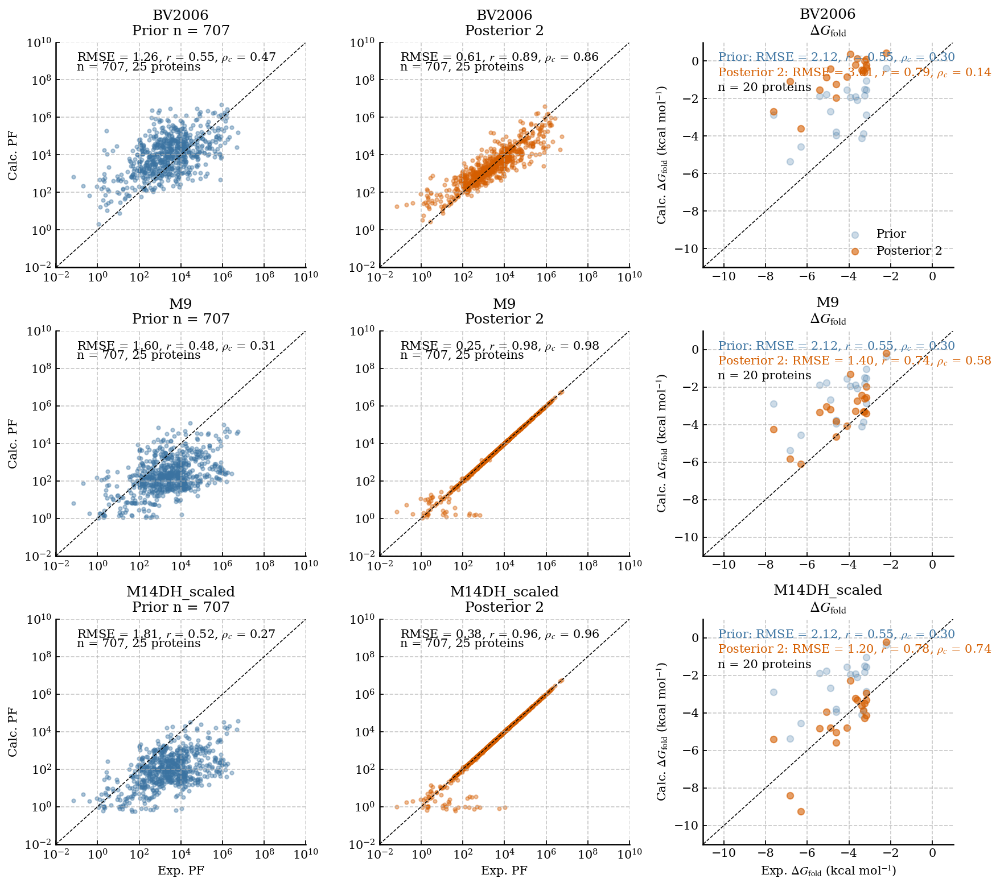

In [23]:
models = ['rewBV2006', 'rewM9', 'rewM14DH_scaled']
model_labels = ['BV2006', 'M9', 'M14DH_scaled']

proteins = ['ACBP', 'ACP', 'alpha3D', 'CLN025', 'GB3', 'HP36', 'Im7', 'NuG2', 'Ubiquitin',
            'EEHEE_rd4_0642-6xHis', 'EEHEE_rd4_0642-No-His',
            'EEHEE_rd4_0871-6xHis', 'EEHEE_rd4_0871-No-His',
            'EEHEE_rd4_0871_K31L_E36V-No-His', 'EHEE_rd2_0005-6xHis',
            'HEEH_rd4_0097-6xHis', 'HHH_rd1_0012-6xHis', 'HHH_rd3_0062-6xHis',
            'HHH_rd4_0518-6xHis', 'HHH_rd4_0518-No-His',
            'HHH_rd4_0518_R35D_G45L-No-His', 'HHH_rd4_0557-6xHis',
            'LysM_0873-No-His', 'LysM_1380-No-His', 'LysM_3314-No-His']

PRIOR_COLOR = "#3B73A1"
POSTERIOR_COLOR = "#D55E00"

# --------------------------------------------------
# Experimental dG
# --------------------------------------------------
exp_dG_all = []
for protein in proteins:
    if os.path.exists(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat'):
        exp_dG_all.append(np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat')[0])
    else:
        exp_dG_all.append(np.nan)
exp_dG_all = np.array(exp_dG_all)

# --------------------------------------------------
# Experimental PFs
# --------------------------------------------------
all_expPF = []
for protein in proteins:
    exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name='rewBV2006')
    expPF = np.array(exp["PF"][idxs])
    all_expPF.append(expPF)
all_expPF = np.concatenate([x for x in all_expPF if len(x) > 0])

# --------------------------------------------------
# Figure
# --------------------------------------------------
fig, axes = plt.subplots(3, 3, figsize=(12, 10.5))
identity_pf = np.logspace(-2, 10, 200)
identity_dG = np.linspace(-12, 2, 200)

for row, (model, model_label) in enumerate(zip(models, model_labels)):

    data = np.load(f'{model}_data_dict.npy', allow_pickle=True).item()
    all_calcPF_prior = np.concatenate([x for x in data['prior PF'] if len(x) > 0])
    all_calcPF_post = np.concatenate([x for x in data['rew PF'] if len(x) > 0])
    dGpcalc_prior = np.array(data['dGp prior'])
    dGpcalc_post = np.array(data['dGp post'])

    # --------------------------------------------------
    # Column 1: PF prior
    # --------------------------------------------------
    ax = axes[row, 0]

    exp_log_pf = np.log10(all_expPF)
    calc_log_pf = np.log10(all_calcPF_prior)
    r = scipy.stats.pearsonr(exp_log_pf, calc_log_pf)[0]
    rmse = RMSE(exp_log_pf, calc_log_pf)
    ccc = calc_ccc(exp_log_pf, calc_log_pf)

    ax.scatter(all_expPF, all_calcPF_prior, color=PRIOR_COLOR, alpha=0.4, s=9, rasterized=True)
    ax.plot(identity_pf, identity_pf, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(1e-2, 1e10); ax.set_ylim(1e-2, 1e10)

    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    ax.set_title(f"{model_label}\nPrior n = {len(all_expPF)}")
    ax.text(1e-1, 1e9, rf"RMSE = {rmse:.2f}, $r$ = {r:.2f}, $\rho_c$ = {ccc:.2f}")
    ax.text(1e-1, 10**8.5, f"n = {len(all_expPF)}, {len(np.unique(proteins))} proteins")

    ax.set_ylabel("Calc. PF")
    if row == 2:
        ax.set_xlabel("Exp. PF")

    # --------------------------------------------------
    # Column 2: PF posterior
    # --------------------------------------------------
    ax = axes[row, 1]

    calc_log_pf = np.log10(all_calcPF_post)
    r = scipy.stats.pearsonr(exp_log_pf, calc_log_pf)[0]
    rmse = RMSE(exp_log_pf, calc_log_pf)
    ccc = calc_ccc(exp_log_pf, calc_log_pf)

    ax.scatter(all_expPF, all_calcPF_post, color=POSTERIOR_COLOR, alpha=0.4, s=9, rasterized=True)
    ax.plot(identity_pf, identity_pf, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(1e-2, 1e10); ax.set_ylim(1e-2, 1e10)

    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    ax.set_title(f"{model_label}\nPosterior 2")
    ax.text(1e-1, 1e9, rf"RMSE = {rmse:.2f}, $r$ = {r:.2f}, $\rho_c$ = {ccc:.2f}")
    ax.text(1e-1, 10**8.5, f"n = {len(all_expPF)}, {len(np.unique(proteins))} proteins")

    if row == 2:
        ax.set_xlabel("Exp. PF")

    # --------------------------------------------------
    # Column 3: dG prior + posterior
    # --------------------------------------------------
    ax = axes[row, 2]

    valid = ~np.isnan(exp_dG_all)
    exp_dG = exp_dG_all[valid]
    calc_dG_prior = dGpcalc_prior[valid]
    calc_dG_post = dGpcalc_post[valid]

    r_prior = scipy.stats.pearsonr(exp_dG, calc_dG_prior)[0]
    rmse_prior = RMSE(exp_dG, calc_dG_prior)
    ccc_prior = calc_ccc(exp_dG, calc_dG_prior)

    r_post = scipy.stats.pearsonr(exp_dG, calc_dG_post)[0]
    rmse_post = RMSE(exp_dG, calc_dG_post)
    ccc_post = calc_ccc(exp_dG, calc_dG_post)

    ax.scatter(exp_dG, calc_dG_prior, color=PRIOR_COLOR, alpha=0.25, s=30, rasterized=True, label='Prior')
    ax.scatter(exp_dG, calc_dG_post, color=POSTERIOR_COLOR, alpha=0.60, s=30, rasterized=True, label='Posterior 2')
    ax.plot(identity_dG, identity_dG, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xlim(-11, 1); ax.set_ylim(-11, 1)

    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    ax.set_title(f"{model_label}\n$\Delta G_{{\\mathrm{{fold}}}}$")
    ax.text(-10.3, 0.0, rf"Prior: RMSE = {rmse_prior:.2f}, $r$ = {r_prior:.2f}, $\rho_c$ = {ccc_prior:.2f}", color=PRIOR_COLOR)
    ax.text(-10.3, -0.8, rf"Posterior 2: RMSE = {rmse_post:.2f}, $r$ = {r_post:.2f}, $\rho_c$ = {ccc_post:.2f}", color=POSTERIOR_COLOR)
    ax.text(-10.3, -1.6, f"n = {len(exp_dG)} proteins")

    ax.set_ylabel(r'Calc. $\Delta G_{\mathrm{fold}}$ (kcal mol$^{-1}$)')
    if row == 2:
        ax.set_xlabel(r'Exp. $\Delta G_{\mathrm{fold}}$ (kcal mol$^{-1}$)')

    if row == 0:
        ax.legend(frameon=False, loc='lower right')

plt.tight_layout()
plt.savefig('pdf_plots/HDX_dG_selected_models_prior_posterior.pdf', dpi=300, bbox_inches='tight')
plt.show()

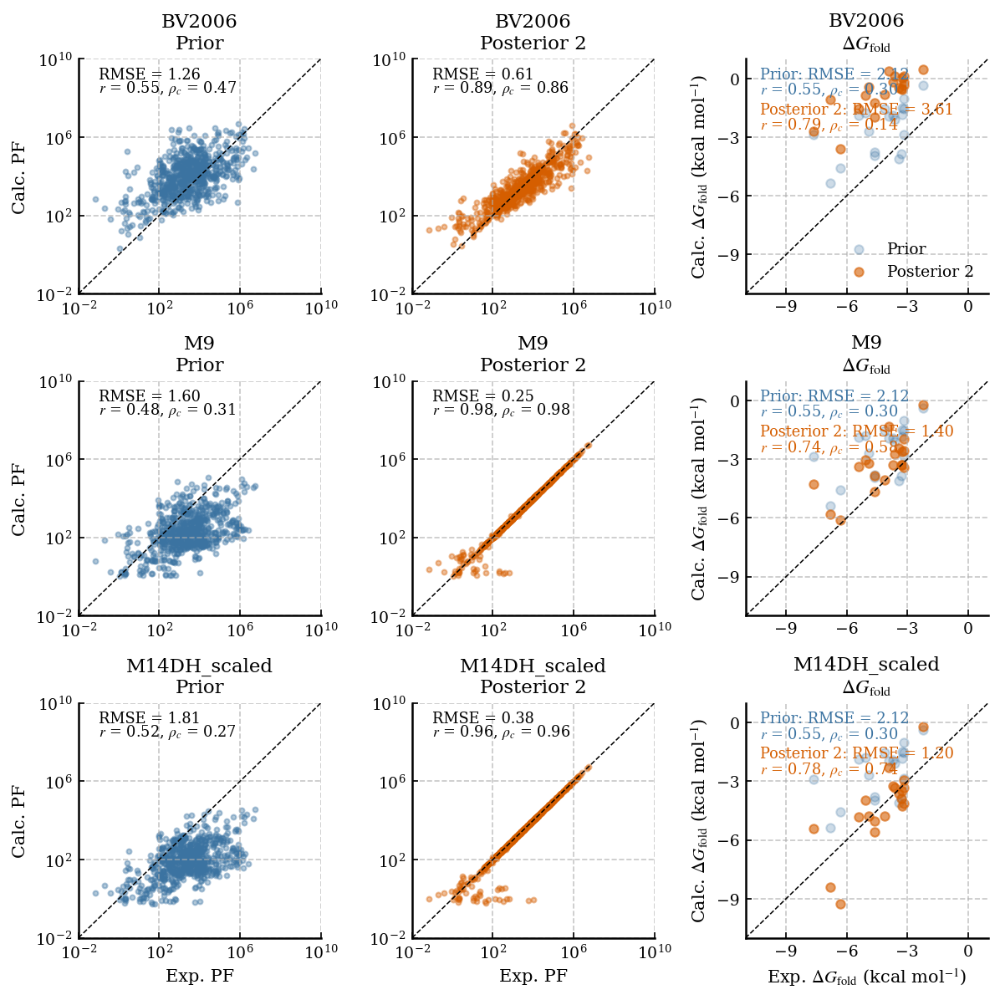

In [27]:
from matplotlib import ticker as mticker

models = ['rewBV2006', 'rewM9', 'rewM14DH_scaled']
model_labels = ['BV2006', 'M9', 'M14DH_scaled']

proteins = ['ACBP', 'ACP', 'alpha3D', 'CLN025', 'GB3', 'HP36', 'Im7', 'NuG2', 'Ubiquitin',
            'EEHEE_rd4_0642-6xHis', 'EEHEE_rd4_0642-No-His',
            'EEHEE_rd4_0871-6xHis', 'EEHEE_rd4_0871-No-His',
            'EEHEE_rd4_0871_K31L_E36V-No-His', 'EHEE_rd2_0005-6xHis',
            'HEEH_rd4_0097-6xHis', 'HHH_rd1_0012-6xHis', 'HHH_rd3_0062-6xHis',
            'HHH_rd4_0518-6xHis', 'HHH_rd4_0518-No-His',
            'HHH_rd4_0518_R35D_G45L-No-His', 'HHH_rd4_0557-6xHis',
            'LysM_0873-No-His', 'LysM_1380-No-His', 'LysM_3314-No-His']

PRIOR_COLOR = "#3B73A1"
POSTERIOR_COLOR = "#D55E00"

TITLE_FONTSIZE = 11
LABEL_FONTSIZE = 10
TICK_FONTSIZE = 9
TEXT_FONTSIZE = 8.5
LEGEND_FONTSIZE = 9

# --------------------------------------------------
# Experimental dG
# --------------------------------------------------
exp_dG_all = []
for protein in proteins:
    if os.path.exists(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat'):
        exp_dG_all.append(np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat')[0])
    else:
        exp_dG_all.append(np.nan)
exp_dG_all = np.array(exp_dG_all)

# --------------------------------------------------
# Experimental PFs
# --------------------------------------------------
all_expPF = []
for protein in proteins:
    exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name='rewBV2006')
    expPF = np.array(exp["PF"][idxs])
    all_expPF.append(expPF)
all_expPF = np.concatenate([x for x in all_expPF if len(x) > 0])

# --------------------------------------------------
# Figure
# --------------------------------------------------
fig, axes = plt.subplots(3, 3, figsize=(8,8))

identity_pf = np.logspace(-2, 10, 200)
identity_dG = np.linspace(-12, 2, 200)

pf_ticks = [1e-2, 1e2, 1e6, 1e10]
dG_ticks = [-9, -6, -3, 0]

for row, (model, model_label) in enumerate(zip(models, model_labels)):

    data = np.load(f'{model}_data_dict.npy', allow_pickle=True).item()

    all_calcPF_prior = np.concatenate([x for x in data['prior PF'] if len(x) > 0])
    all_calcPF_post = np.concatenate([x for x in data['rew PF'] if len(x) > 0])

    dGpcalc_prior = np.array(data['dGp prior'])
    dGpcalc_post = np.array(data['dGp post'])

    exp_log_pf = np.log10(all_expPF)

    # --------------------------------------------------
    # Column 1: PF prior
    # --------------------------------------------------
    ax = axes[row, 0]

    calc_log_pf = np.log10(all_calcPF_prior)
    r = scipy.stats.pearsonr(exp_log_pf, calc_log_pf)[0]
    rmse = RMSE(exp_log_pf, calc_log_pf)
    ccc = calc_ccc(exp_log_pf, calc_log_pf)

    ax.scatter(all_expPF, all_calcPF_prior, color=PRIOR_COLOR, alpha=0.4, s=8, rasterized=True)
    ax.plot(identity_pf, identity_pf, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(1e-2, 1e10); ax.set_ylim(1e-2, 1e10)
    ax.set_xticks(pf_ticks); ax.set_yticks(pf_ticks)
    ax.xaxis.set_minor_locator(mticker.NullLocator()); ax.yaxis.set_minor_locator(mticker.NullLocator())

    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False, labelsize=TICK_FONTSIZE)

    ax.set_title(f"{model_label}\nPrior", fontsize=TITLE_FONTSIZE)
    ax.text(1e-1, 1e9, rf"RMSE = {rmse:.2f}", fontsize=TEXT_FONTSIZE)
    ax.text(1e-1, 10**8.3, rf"$r$ = {r:.2f}, $\rho_c$ = {ccc:.2f}", fontsize=TEXT_FONTSIZE)

    ax.set_ylabel("Calc. PF", fontsize=LABEL_FONTSIZE)
    if row == 2:
        ax.set_xlabel("Exp. PF", fontsize=LABEL_FONTSIZE)

    # --------------------------------------------------
    # Column 2: PF posterior
    # --------------------------------------------------
    ax = axes[row, 1]

    calc_log_pf = np.log10(all_calcPF_post)
    r = scipy.stats.pearsonr(exp_log_pf, calc_log_pf)[0]
    rmse = RMSE(exp_log_pf, calc_log_pf)
    ccc = calc_ccc(exp_log_pf, calc_log_pf)

    ax.scatter(all_expPF, all_calcPF_post, color=POSTERIOR_COLOR, alpha=0.4, s=8, rasterized=True)
    ax.plot(identity_pf, identity_pf, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(1e-2, 1e10); ax.set_ylim(1e-2, 1e10)
    ax.set_xticks(pf_ticks); ax.set_yticks(pf_ticks)
    ax.xaxis.set_minor_locator(mticker.NullLocator()); ax.yaxis.set_minor_locator(mticker.NullLocator())

    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False, labelsize=TICK_FONTSIZE)

    ax.set_title(f"{model_label}\nPosterior 2", fontsize=TITLE_FONTSIZE)
    ax.text(1e-1, 1e9, rf"RMSE = {rmse:.2f}", fontsize=TEXT_FONTSIZE)
    ax.text(1e-1, 10**8.3, rf"$r$ = {r:.2f}, $\rho_c$ = {ccc:.2f}", fontsize=TEXT_FONTSIZE)

    if row == 2:
        ax.set_xlabel("Exp. PF", fontsize=LABEL_FONTSIZE)

    # --------------------------------------------------
    # Column 3: dG prior + posterior
    # --------------------------------------------------
    ax = axes[row, 2]

    valid = ~np.isnan(exp_dG_all)
    exp_dG = exp_dG_all[valid]
    calc_dG_prior = dGpcalc_prior[valid]
    calc_dG_post = dGpcalc_post[valid]

    r_prior = scipy.stats.pearsonr(exp_dG, calc_dG_prior)[0]
    rmse_prior = RMSE(exp_dG, calc_dG_prior)
    ccc_prior = calc_ccc(exp_dG, calc_dG_prior)

    r_post = scipy.stats.pearsonr(exp_dG, calc_dG_post)[0]
    rmse_post = RMSE(exp_dG, calc_dG_post)
    ccc_post = calc_ccc(exp_dG, calc_dG_post)

    ax.scatter(exp_dG, calc_dG_prior, color=PRIOR_COLOR, alpha=0.25, s=25, rasterized=True, label='Prior')
    ax.scatter(exp_dG, calc_dG_post, color=POSTERIOR_COLOR, alpha=0.60, s=25, rasterized=True, label='Posterior 2')
    ax.plot(identity_dG, identity_dG, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xlim(-11, 1); ax.set_ylim(-11, 1)
    ax.set_xticks(dG_ticks); ax.set_yticks(dG_ticks)

    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False, labelsize=TICK_FONTSIZE)

    ax.set_title(f"{model_label}\n$\Delta G_{{\\mathrm{{fold}}}}$", fontsize=TITLE_FONTSIZE)

    ax.text(-10.3, 0.0, rf"Prior: RMSE = {rmse_prior:.2f}", color=PRIOR_COLOR, fontsize=TEXT_FONTSIZE)
    ax.text(-10.3, -0.8, rf"$r$ = {r_prior:.2f}, $\rho_c$ = {ccc_prior:.2f}", color=PRIOR_COLOR, fontsize=TEXT_FONTSIZE)

    ax.text(-10.3, -1.8, rf"Posterior 2: RMSE = {rmse_post:.2f}", color=POSTERIOR_COLOR, fontsize=TEXT_FONTSIZE)
    ax.text(-10.3, -2.6, rf"$r$ = {r_post:.2f}, $\rho_c$ = {ccc_post:.2f}", color=POSTERIOR_COLOR, fontsize=TEXT_FONTSIZE)

    ax.set_ylabel(r'Calc. $\Delta G_{\mathrm{fold}}$ (kcal mol$^{-1}$)', fontsize=LABEL_FONTSIZE)
    if row == 2:
        ax.set_xlabel(r'Exp. $\Delta G_{\mathrm{fold}}$ (kcal mol$^{-1}$)', fontsize=LABEL_FONTSIZE)

    if row == 0:
        ax.legend(frameon=False, loc='lower right', fontsize=LEGEND_FONTSIZE)

plt.tight_layout(pad=0.8, w_pad=1.0, h_pad=1.0)
plt.savefig('pdf_plots/HDX_dG_selected_models_prior_posterior.pdf', dpi=300, bbox_inches='tight')
plt.show()

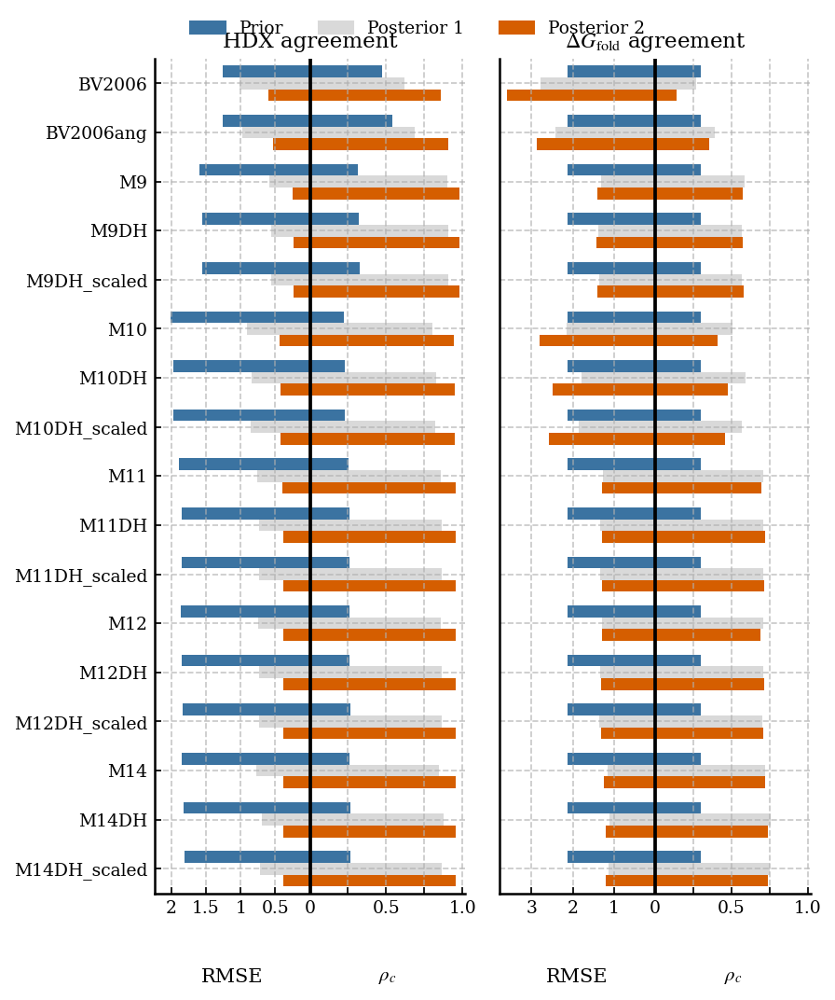

In [43]:
# summary barplots of model performances: HDX (left panel) and dG (right panel)

# left side of each panel = RMSE, right side = rho_c (0 to 1)
# HDX RMSE = 0 to 2.2; dG RMSE = 0 to 3.7
# model order: BV2006 at top, M14DH_scaled at bottom

models = ['rewBV2006', 'rewBV2006ang',
          'rewM9', 'rewM9DH', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH', 'rewM10DH_scaled',
          'rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH', 'rewM12DH_scaled',
          'rewM14', 'rewM14DH', 'rewM14DH_scaled']
model_labels = [m[3:] for m in models]

proteins = ['ACBP', 'ACP', 'alpha3D', 'CLN025', 'GB3', 'HP36', 'Im7', 'NuG2', 'Ubiquitin',
            'EEHEE_rd4_0642-6xHis', 'EEHEE_rd4_0642-No-His',
            'EEHEE_rd4_0871-6xHis', 'EEHEE_rd4_0871-No-His',
            'EEHEE_rd4_0871_K31L_E36V-No-His', 'EHEE_rd2_0005-6xHis',
            'HEEH_rd4_0097-6xHis', 'HHH_rd1_0012-6xHis', 'HHH_rd3_0062-6xHis',
            'HHH_rd4_0518-6xHis', 'HHH_rd4_0518-No-His',
            'HHH_rd4_0518_R35D_G45L-No-His', 'HHH_rd4_0557-6xHis',
            'LysM_0873-No-His', 'LysM_1380-No-His', 'LysM_3314-No-His']

COLOR3 = "#3B73A1"  # prior
COLOR2 = "#D9D9D9"  # posterior 1: elbow
COLOR1 = "#D55E00"  # posterior 2

TITLE_FONTSIZE = 11
LABEL_FONTSIZE = 10
TICK_FONTSIZE = 9
LEGEND_FONTSIZE = 9

# --------------------------------------------------
# Storage
# --------------------------------------------------

rmse_HDX_prior, rmse_HDX_post1, rmse_HDX_post2 = [], [], []
ccc_HDX_prior, ccc_HDX_post1, ccc_HDX_post2 = [], [], []
rmse_dG_prior, rmse_dG_post1, rmse_dG_post2 = [], [], []
ccc_dG_prior, ccc_dG_post1, ccc_dG_post2 = [], [], []

# --------------------------------------------------
# Experimental dG
# --------------------------------------------------

exp_dG_all = []
for protein in proteins:
    if os.path.exists(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat'):
        exp_dG_all.append(np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat')[0])
    else:
        exp_dG_all.append(np.nan)

exp_dG_all = np.array(exp_dG_all)
valid = ~np.isnan(exp_dG_all)
exp_dG = exp_dG_all[valid]

# --------------------------------------------------
# Experimental PFs
# --------------------------------------------------

all_expPF = []
for protein in proteins:
    exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name='rewBV2006')
    all_expPF.append(np.array(exp["PF"][idxs]))

all_expPF = np.concatenate([x for x in all_expPF if len(x) > 0])
x_exp = np.log10(all_expPF)

# --------------------------------------------------
# Loop over models
# --------------------------------------------------

for model in models:

    data_post1 = np.load(f'../Folding_landscapes/{model}_data_dict_elbow_posterior.npy', allow_pickle=True).item()
    data_post2 = np.load(f'../Folding_landscapes/{model}_data_dict.npy', allow_pickle=True).item()

    all_calcPF_prior = np.concatenate([x for x in data_post2['prior PF'] if len(x) > 0])
    all_calcPF_post1 = np.concatenate([x for x in data_post1['rew PF'] if len(x) > 0])
    all_calcPF_post2 = np.concatenate([x for x in data_post2['rew PF'] if len(x) > 0])

    dGpcalc_prior = np.array(data_post2['dGp prior'])[valid]
    dGpcalc_post1 = np.array(data_post1['dGp post'])[valid]
    dGpcalc_post2 = np.array(data_post2['dGp post'])[valid]

    if len(all_calcPF_prior) != len(all_expPF): raise ValueError(f"{model}: prior PF length mismatch: calc={len(all_calcPF_prior)}, exp={len(all_expPF)}")
    if len(all_calcPF_post1) != len(all_expPF): raise ValueError(f"{model}: posterior 1 PF length mismatch: calc={len(all_calcPF_post1)}, exp={len(all_expPF)}")
    if len(all_calcPF_post2) != len(all_expPF): raise ValueError(f"{model}: posterior 2 PF length mismatch: calc={len(all_calcPF_post2)}, exp={len(all_expPF)}")
    if len(dGpcalc_prior) != len(exp_dG): raise ValueError(f"{model}: prior dG length mismatch: calc={len(dGpcalc_prior)}, exp={len(exp_dG)}")
    if len(dGpcalc_post1) != len(exp_dG): raise ValueError(f"{model}: posterior 1 dG length mismatch: calc={len(dGpcalc_post1)}, exp={len(exp_dG)}")
    if len(dGpcalc_post2) != len(exp_dG): raise ValueError(f"{model}: posterior 2 dG length mismatch: calc={len(dGpcalc_post2)}, exp={len(exp_dG)}")

    y_prior = np.log10(all_calcPF_prior)
    y_post1 = np.log10(all_calcPF_post1)
    y_post2 = np.log10(all_calcPF_post2)

    rmse_HDX_prior.append(RMSE(x_exp, y_prior))
    rmse_HDX_post1.append(RMSE(x_exp, y_post1))
    rmse_HDX_post2.append(RMSE(x_exp, y_post2))

    ccc_HDX_prior.append(calc_ccc(x_exp, y_prior))
    ccc_HDX_post1.append(calc_ccc(x_exp, y_post1))
    ccc_HDX_post2.append(calc_ccc(x_exp, y_post2))

    rmse_dG_prior.append(RMSE(exp_dG, dGpcalc_prior))
    rmse_dG_post1.append(RMSE(exp_dG, dGpcalc_post1))
    rmse_dG_post2.append(RMSE(exp_dG, dGpcalc_post2))

    ccc_dG_prior.append(calc_ccc(exp_dG, dGpcalc_prior))
    ccc_dG_post1.append(calc_ccc(exp_dG, dGpcalc_post1))
    ccc_dG_post2.append(calc_ccc(exp_dG, dGpcalc_post2))

# --------------------------------------------------
# Plot
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(6, 7), sharey=True)

y = np.arange(len(models))
bar_h = 0.24

def make_panel(ax, rmse_prior, rmse_post1, rmse_post2, ccc_prior, ccc_post1, ccc_post2, title, rmse_max, rmse_tick_vals):

    rmse_prior_scaled = np.array(rmse_prior) / rmse_max
    rmse_post1_scaled = np.array(rmse_post1) / rmse_max
    rmse_post2_scaled = np.array(rmse_post2) / rmse_max

    ax.barh(y - bar_h, -rmse_prior_scaled, height=bar_h, color=COLOR3, label='Prior')
    ax.barh(y,         -rmse_post1_scaled, height=bar_h, color=COLOR2, label='Posterior 1')
    ax.barh(y + bar_h, -rmse_post2_scaled, height=bar_h, color=COLOR1, label='Posterior 2')

    ax.barh(y - bar_h, np.array(ccc_prior), height=bar_h, color=COLOR3)
    ax.barh(y,         np.array(ccc_post1), height=bar_h, color=COLOR2)
    ax.barh(y + bar_h, np.array(ccc_post2), height=bar_h, color=COLOR1)

    ax.axvline(0, color='black', linewidth=1.8)

    rhoc_tick_vals = [0, 0.25, 0.50, 0.75, 1.00]

    rmse_tick_pos = [-v / rmse_max for v in rmse_tick_vals[::-1]]
    rhoc_tick_pos = rhoc_tick_vals[1:]
    xticks = rmse_tick_pos + rhoc_tick_pos
    xticklabels = [f'{v:g}' for v in rmse_tick_vals[::-1]] + ['', '0.5', '', '1.0']

    ax.set_xlim(-1.02, 1.02)
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticklabels, fontsize=TICK_FONTSIZE)

    ax.set_yticks(y)
    ax.set_yticklabels(model_labels, fontsize=TICK_FONTSIZE)

    # BV2006 at top, M14DH_scaled at bottom
    ax.set_ylim(len(models) - 0.5, -0.5)

    ax.set_title(title, fontsize=TITLE_FONTSIZE)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False, labelsize=TICK_FONTSIZE)

    ax.text(0.25, -0.09, "RMSE", transform=ax.transAxes, ha='center', va='top', fontsize=LABEL_FONTSIZE)
    ax.text(0.75, -0.09, r'$\rho_c$', transform=ax.transAxes, ha='center', va='top', fontsize=LABEL_FONTSIZE)

make_panel(axes[0], rmse_HDX_prior, rmse_HDX_post1, rmse_HDX_post2, ccc_HDX_prior, ccc_HDX_post1, ccc_HDX_post2, "HDX agreement", 2.2, [0, 0.5, 1.0, 1.5, 2.0])
make_panel(axes[1], rmse_dG_prior, rmse_dG_post1, rmse_dG_post2, ccc_dG_prior, ccc_dG_post1, ccc_dG_post2, r'$\Delta G_{\mathrm{fold}}$ agreement', 3.7, [0, 1.0, 2.0, 3.0])

axes[1].tick_params(axis='y', left=False, labelleft=False)

handles = [plt.Rectangle((0, 0), 1, 1, color=COLOR3),
           plt.Rectangle((0, 0), 1, 1, color=COLOR2),
           plt.Rectangle((0, 0), 1, 1, color=COLOR1)]

fig.legend(handles, ['Prior', 'Posterior 1', 'Posterior 2'], frameon=False, fontsize=LEGEND_FONTSIZE, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.01))

plt.tight_layout(pad=0.8, w_pad=1.2)
plt.savefig("pdf_plots/models_summary_HDX_dG_RMSE_rhoc_horizontal_barplots_all.pdf", dpi=300, bbox_inches="tight")
plt.show()

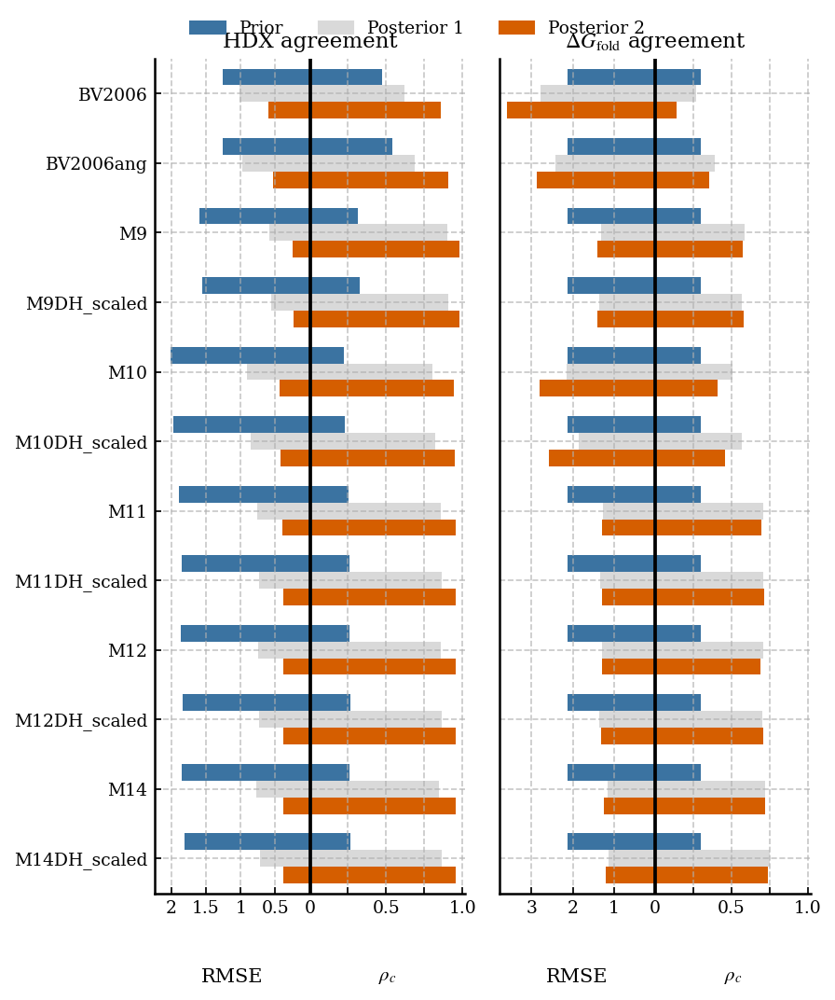

In [41]:
# summary barplots of model performances: HDX (left panel) and dG (right panel)

# left side of each panel = RMSE, right side = rho_c (0 to 1)
# HDX RMSE = 0 to 2.2; dG RMSE = 0 to 3.7
# model order: BV2006 at top, M14DH_scaled at bottom

models = ['rewBV2006', 'rewBV2006ang',
          'rewM9', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH_scaled',
          'rewM11', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH_scaled',
          'rewM14', 'rewM14DH_scaled']
model_labels = [m[3:] for m in models]

proteins = ['ACBP', 'ACP', 'alpha3D', 'CLN025', 'GB3', 'HP36', 'Im7', 'NuG2', 'Ubiquitin',
            'EEHEE_rd4_0642-6xHis', 'EEHEE_rd4_0642-No-His',
            'EEHEE_rd4_0871-6xHis', 'EEHEE_rd4_0871-No-His',
            'EEHEE_rd4_0871_K31L_E36V-No-His', 'EHEE_rd2_0005-6xHis',
            'HEEH_rd4_0097-6xHis', 'HHH_rd1_0012-6xHis', 'HHH_rd3_0062-6xHis',
            'HHH_rd4_0518-6xHis', 'HHH_rd4_0518-No-His',
            'HHH_rd4_0518_R35D_G45L-No-His', 'HHH_rd4_0557-6xHis',
            'LysM_0873-No-His', 'LysM_1380-No-His', 'LysM_3314-No-His']

COLOR3 = "#3B73A1"  # prior
COLOR2 = "#D9D9D9"  # posterior 1: elbow
COLOR1 = "#D55E00"  # posterior 2

TITLE_FONTSIZE = 11
LABEL_FONTSIZE = 10
TICK_FONTSIZE = 9
LEGEND_FONTSIZE = 9

# --------------------------------------------------
# Storage
# --------------------------------------------------

rmse_HDX_prior, rmse_HDX_post1, rmse_HDX_post2 = [], [], []
ccc_HDX_prior, ccc_HDX_post1, ccc_HDX_post2 = [], [], []
rmse_dG_prior, rmse_dG_post1, rmse_dG_post2 = [], [], []
ccc_dG_prior, ccc_dG_post1, ccc_dG_post2 = [], [], []

# --------------------------------------------------
# Experimental dG
# --------------------------------------------------

exp_dG_all = []
for protein in proteins:
    if os.path.exists(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat'):
        exp_dG_all.append(np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat')[0])
    else:
        exp_dG_all.append(np.nan)

exp_dG_all = np.array(exp_dG_all)
valid = ~np.isnan(exp_dG_all)
exp_dG = exp_dG_all[valid]

# --------------------------------------------------
# Experimental PFs
# --------------------------------------------------

all_expPF = []
for protein in proteins:
    exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name='rewBV2006')
    all_expPF.append(np.array(exp["PF"][idxs]))

all_expPF = np.concatenate([x for x in all_expPF if len(x) > 0])
x_exp = np.log10(all_expPF)

# --------------------------------------------------
# Loop over models
# --------------------------------------------------

for model in models:

    data_post1 = np.load(f'../Folding_landscapes/{model}_data_dict_elbow_posterior.npy', allow_pickle=True).item()
    data_post2 = np.load(f'../Folding_landscapes/{model}_data_dict.npy', allow_pickle=True).item()

    all_calcPF_prior = np.concatenate([x for x in data_post2['prior PF'] if len(x) > 0])
    all_calcPF_post1 = np.concatenate([x for x in data_post1['rew PF'] if len(x) > 0])
    all_calcPF_post2 = np.concatenate([x for x in data_post2['rew PF'] if len(x) > 0])

    dGpcalc_prior = np.array(data_post2['dGp prior'])[valid]
    dGpcalc_post1 = np.array(data_post1['dGp post'])[valid]
    dGpcalc_post2 = np.array(data_post2['dGp post'])[valid]

    if len(all_calcPF_prior) != len(all_expPF): raise ValueError(f"{model}: prior PF length mismatch: calc={len(all_calcPF_prior)}, exp={len(all_expPF)}")
    if len(all_calcPF_post1) != len(all_expPF): raise ValueError(f"{model}: posterior 1 PF length mismatch: calc={len(all_calcPF_post1)}, exp={len(all_expPF)}")
    if len(all_calcPF_post2) != len(all_expPF): raise ValueError(f"{model}: posterior 2 PF length mismatch: calc={len(all_calcPF_post2)}, exp={len(all_expPF)}")
    if len(dGpcalc_prior) != len(exp_dG): raise ValueError(f"{model}: prior dG length mismatch: calc={len(dGpcalc_prior)}, exp={len(exp_dG)}")
    if len(dGpcalc_post1) != len(exp_dG): raise ValueError(f"{model}: posterior 1 dG length mismatch: calc={len(dGpcalc_post1)}, exp={len(exp_dG)}")
    if len(dGpcalc_post2) != len(exp_dG): raise ValueError(f"{model}: posterior 2 dG length mismatch: calc={len(dGpcalc_post2)}, exp={len(exp_dG)}")

    y_prior = np.log10(all_calcPF_prior)
    y_post1 = np.log10(all_calcPF_post1)
    y_post2 = np.log10(all_calcPF_post2)

    rmse_HDX_prior.append(RMSE(x_exp, y_prior))
    rmse_HDX_post1.append(RMSE(x_exp, y_post1))
    rmse_HDX_post2.append(RMSE(x_exp, y_post2))

    ccc_HDX_prior.append(calc_ccc(x_exp, y_prior))
    ccc_HDX_post1.append(calc_ccc(x_exp, y_post1))
    ccc_HDX_post2.append(calc_ccc(x_exp, y_post2))

    rmse_dG_prior.append(RMSE(exp_dG, dGpcalc_prior))
    rmse_dG_post1.append(RMSE(exp_dG, dGpcalc_post1))
    rmse_dG_post2.append(RMSE(exp_dG, dGpcalc_post2))

    ccc_dG_prior.append(calc_ccc(exp_dG, dGpcalc_prior))
    ccc_dG_post1.append(calc_ccc(exp_dG, dGpcalc_post1))
    ccc_dG_post2.append(calc_ccc(exp_dG, dGpcalc_post2))

# --------------------------------------------------
# Plot
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(6, 7), sharey=True)

y = np.arange(len(models))
bar_h = 0.24

def make_panel(ax, rmse_prior, rmse_post1, rmse_post2, ccc_prior, ccc_post1, ccc_post2, title, rmse_max, rmse_tick_vals):

    rmse_prior_scaled = np.array(rmse_prior) / rmse_max
    rmse_post1_scaled = np.array(rmse_post1) / rmse_max
    rmse_post2_scaled = np.array(rmse_post2) / rmse_max

    ax.barh(y - bar_h, -rmse_prior_scaled, height=bar_h, color=COLOR3, label='Prior')
    ax.barh(y,         -rmse_post1_scaled, height=bar_h, color=COLOR2, label='Posterior 1')
    ax.barh(y + bar_h, -rmse_post2_scaled, height=bar_h, color=COLOR1, label='Posterior 2')

    ax.barh(y - bar_h, np.array(ccc_prior), height=bar_h, color=COLOR3)
    ax.barh(y,         np.array(ccc_post1), height=bar_h, color=COLOR2)
    ax.barh(y + bar_h, np.array(ccc_post2), height=bar_h, color=COLOR1)

    ax.axvline(0, color='black', linewidth=1.8)

    rhoc_tick_vals = [0, 0.25, 0.50, 0.75, 1.00]

    rmse_tick_pos = [-v / rmse_max for v in rmse_tick_vals[::-1]]
    rhoc_tick_pos = rhoc_tick_vals[1:]
    xticks = rmse_tick_pos + rhoc_tick_pos
    xticklabels = [f'{v:g}' for v in rmse_tick_vals[::-1]] + ['', '0.5', '', '1.0']

    ax.set_xlim(-1.02, 1.02)
    ax.set_xticks(xticks)
    ax.set_xticklabels(xticklabels, fontsize=TICK_FONTSIZE)

    ax.set_yticks(y)
    ax.set_yticklabels(model_labels, fontsize=TICK_FONTSIZE)

    # BV2006 at top, M14DH_scaled at bottom
    ax.set_ylim(len(models) - 0.5, -0.5)

    ax.set_title(title, fontsize=TITLE_FONTSIZE)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False, labelsize=TICK_FONTSIZE)

    ax.text(0.25, -0.09, "RMSE", transform=ax.transAxes, ha='center', va='top', fontsize=LABEL_FONTSIZE)
    ax.text(0.75, -0.09, r'$\rho_c$', transform=ax.transAxes, ha='center', va='top', fontsize=LABEL_FONTSIZE)

make_panel(axes[0], rmse_HDX_prior, rmse_HDX_post1, rmse_HDX_post2, ccc_HDX_prior, ccc_HDX_post1, ccc_HDX_post2, "HDX agreement", 2.2, [0, 0.5, 1.0, 1.5, 2.0])
make_panel(axes[1], rmse_dG_prior, rmse_dG_post1, rmse_dG_post2, ccc_dG_prior, ccc_dG_post1, ccc_dG_post2, r'$\Delta G_{\mathrm{fold}}$ agreement', 3.7, [0, 1.0, 2.0, 3.0])

axes[1].tick_params(axis='y', left=False, labelleft=False)

handles = [plt.Rectangle((0, 0), 1, 1, color=COLOR3),
           plt.Rectangle((0, 0), 1, 1, color=COLOR2),
           plt.Rectangle((0, 0), 1, 1, color=COLOR1)]

fig.legend(handles, ['Prior', 'Posterior 1', 'Posterior 2'], frameon=False, fontsize=LEGEND_FONTSIZE, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.01))

plt.tight_layout(pad=0.8, w_pad=1.2)
plt.savefig("pdf_plots/models_summary_HDX_dG_RMSE_rhoc_horizontal_barplots.pdf", dpi=300, bbox_inches="tight")
plt.show()

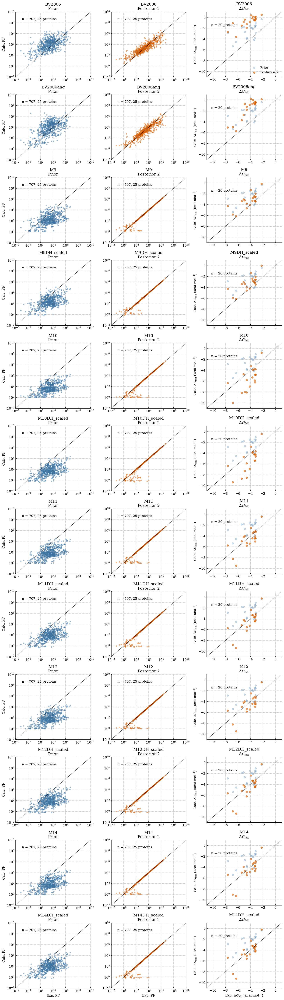

In [9]:
models = ['rewBV2006', 'rewBV2006ang',
          'rewM9', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH_scaled',
          'rewM11', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH_scaled',
          'rewM14', 'rewM14DH_scaled']
model_labels = [m[3:] for m in models]

proteins = ['ACBP', 'ACP', 'alpha3D', 'CLN025', 'GB3', 'HP36', 'Im7', 'NuG2', 'Ubiquitin',
            'EEHEE_rd4_0642-6xHis', 'EEHEE_rd4_0642-No-His',
            'EEHEE_rd4_0871-6xHis', 'EEHEE_rd4_0871-No-His',
            'EEHEE_rd4_0871_K31L_E36V-No-His', 'EHEE_rd2_0005-6xHis',
            'HEEH_rd4_0097-6xHis', 'HHH_rd1_0012-6xHis', 'HHH_rd3_0062-6xHis',
            'HHH_rd4_0518-6xHis', 'HHH_rd4_0518-No-His',
            'HHH_rd4_0518_R35D_G45L-No-His', 'HHH_rd4_0557-6xHis',
            'LysM_0873-No-His', 'LysM_1380-No-His', 'LysM_3314-No-His']

PRIOR_COLOR = "#3B73A1"
POSTERIOR_COLOR = "#D55E00"

# --------------------------------------------------
# Experimental dG
# --------------------------------------------------
exp_dG_all = []
for protein in proteins:
    if os.path.exists(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat'):
        exp_dG_all.append(np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat')[0])
    else:
        exp_dG_all.append(np.nan)
exp_dG_all = np.array(exp_dG_all)

# --------------------------------------------------
# Experimental PFs
# --------------------------------------------------
all_expPF = []
for protein in proteins:
    exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name='rewBV2006')
    expPF = np.array(exp["PF"][idxs])
    all_expPF.append(expPF)
all_expPF = np.concatenate([x for x in all_expPF if len(x) > 0])

# --------------------------------------------------
# Figure
# --------------------------------------------------
nrows = len(models)
fig, axes = plt.subplots(nrows, 3, figsize=(12, 3.5 * nrows))
identity_pf = np.logspace(-2, 10, 200)
identity_dG = np.linspace(-17, 2, 200)

for row, (model, model_label) in enumerate(zip(models, model_labels)):

    data = np.load(f'{model}_data_dict.npy', allow_pickle=True).item()
    all_calcPF_prior = np.concatenate([x for x in data['prior PF'] if len(x) > 0])
    all_calcPF_post = np.concatenate([x for x in data['rew PF'] if len(x) > 0])
    dGpcalc_prior = np.array(data['dGp prior'])
    dGpcalc_post = np.array(data['dGp post'])

    # --------------------------------------------------
    # Column 1: PF prior
    # --------------------------------------------------
    ax = axes[row, 0]

    exp_log_pf = np.log10(all_expPF)
    calc_log_pf = np.log10(all_calcPF_prior)
    r = scipy.stats.pearsonr(exp_log_pf, calc_log_pf)[0]
    rmse = RMSE(exp_log_pf, calc_log_pf)
    ccc = calc_ccc(exp_log_pf, calc_log_pf)

    ax.scatter(all_expPF, all_calcPF_prior, color=PRIOR_COLOR, alpha=0.4, s=9, rasterized=True)
    ax.plot(identity_pf, identity_pf, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(1e-2, 1e10); ax.set_ylim(1e-2, 1e10)

    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    ax.set_title(f"{model_label}\nPrior")
    #ax.text(1e-1, 1e9, rf"RMSE = {rmse:.2f}, $r$ = {r:.2f}, $\rho_c$ = {ccc:.2f}")
    ax.text(1e-1, 10**8.5, f"n = {len(all_expPF)}, {len(np.unique(proteins))} proteins")

    ax.set_ylabel("Calc. PF")
    if row == nrows - 1:
        ax.set_xlabel("Exp. PF")

    # --------------------------------------------------
    # Column 2: PF posterior
    # --------------------------------------------------
    ax = axes[row, 1]

    calc_log_pf = np.log10(all_calcPF_post)
    r = scipy.stats.pearsonr(exp_log_pf, calc_log_pf)[0]
    rmse = RMSE(exp_log_pf, calc_log_pf)
    ccc = calc_ccc(exp_log_pf, calc_log_pf)

    ax.scatter(all_expPF, all_calcPF_post, color=POSTERIOR_COLOR, alpha=0.4, s=9, rasterized=True)
    ax.plot(identity_pf, identity_pf, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(1e-2, 1e10); ax.set_ylim(1e-2, 1e10)

    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    ax.set_title(f"{model_label}\nPosterior 2")
    #ax.text(1e-1, 1e9, rf"RMSE = {rmse:.2f}, $r$ = {r:.2f}, $\rho_c$ = {ccc:.2f}")
    ax.text(1e-1, 10**8.5, f"n = {len(all_expPF)}, {len(np.unique(proteins))} proteins")

    if row == nrows - 1:
        ax.set_xlabel("Exp. PF")

    # --------------------------------------------------
    # Column 3: dG prior + posterior
    # --------------------------------------------------
    ax = axes[row, 2]

    valid = ~np.isnan(exp_dG_all)
    exp_dG = exp_dG_all[valid]
    calc_dG_prior = dGpcalc_prior[valid]
    calc_dG_post = dGpcalc_post[valid]

    r_prior = scipy.stats.pearsonr(exp_dG, calc_dG_prior)[0]
    rmse_prior = RMSE(exp_dG, calc_dG_prior)
    ccc_prior = calc_ccc(exp_dG, calc_dG_prior)

    r_post = scipy.stats.pearsonr(exp_dG, calc_dG_post)[0]
    rmse_post = RMSE(exp_dG, calc_dG_post)
    ccc_post = calc_ccc(exp_dG, calc_dG_post)

    ax.scatter(exp_dG, calc_dG_prior, color=PRIOR_COLOR, alpha=0.25, s=30, rasterized=True, label='Prior')
    ax.scatter(exp_dG, calc_dG_post, color=POSTERIOR_COLOR, alpha=0.60, s=30, rasterized=True, label='Posterior 2')
    ax.plot(identity_dG, identity_dG, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xlim(-11, 1); ax.set_ylim(-11, 1)

    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    ax.set_title(f"{model_label}\n$\Delta G_{{\\mathrm{{fold}}}}$")
    #ax.text(-10.3, 0.0, rf"Prior: RMSE = {rmse_prior:.2f}, $r$ = {r_prior:.2f}, $\rho_c$ = {ccc_prior:.2f}", color=PRIOR_COLOR)
    #ax.text(-10.3, -0.8, rf"Posterior 2: RMSE = {rmse_post:.2f}, $r$ = {r_post:.2f}, $\rho_c$ = {ccc_post:.2f}", color=POSTERIOR_COLOR)
    ax.text(-10.3, -1.6, f"n = {len(exp_dG)} proteins")

    ax.set_ylabel(r'Calc. $\Delta G_{\mathrm{fold}}$ (kcal mol$^{-1}$)')
    if row == nrows - 1:
        ax.set_xlabel(r'Exp. $\Delta G_{\mathrm{fold}}$ (kcal mol$^{-1}$)')

    if row == 0:
        ax.legend(frameon=False, loc='lower right')

plt.tight_layout()
plt.savefig('pdf_plots/HDX_dG_all_models_prior_posterior.pdf', dpi=300, bbox_inches='tight')
plt.show()

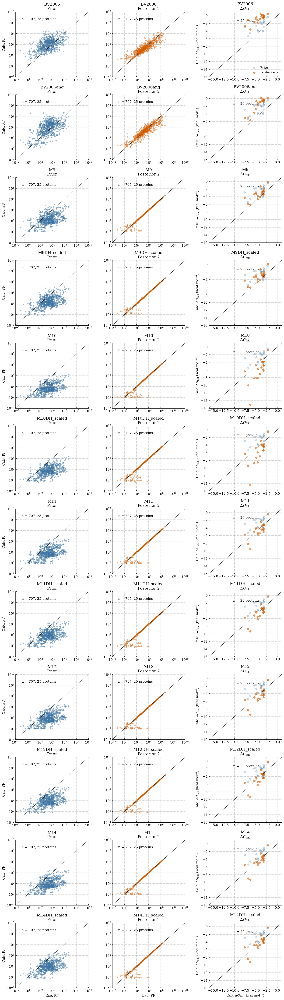

In [ ]:
models = ['rewBV2006', 'rewBV2006ang',
          'rewM9', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH_scaled',
          'rewM11', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH_scaled',
          'rewM14', 'rewM14DH_scaled']
model_labels = [m[3:] for m in models]

proteins = ['ACBP', 'ACP', 'alpha3D', 'CLN025', 'GB3', 'HP36', 'Im7', 'NuG2', 'Ubiquitin',
            'EEHEE_rd4_0642-6xHis', 'EEHEE_rd4_0642-No-His',
            'EEHEE_rd4_0871-6xHis', 'EEHEE_rd4_0871-No-His',
            'EEHEE_rd4_0871_K31L_E36V-No-His', 'EHEE_rd2_0005-6xHis',
            'HEEH_rd4_0097-6xHis', 'HHH_rd1_0012-6xHis', 'HHH_rd3_0062-6xHis',
            'HHH_rd4_0518-6xHis', 'HHH_rd4_0518-No-His',
            'HHH_rd4_0518_R35D_G45L-No-His', 'HHH_rd4_0557-6xHis',
            'LysM_0873-No-His', 'LysM_1380-No-His', 'LysM_3314-No-His']

PRIOR_COLOR = "#3B73A1"
POSTERIOR_COLOR = "#D55E00"

# --------------------------------------------------
# Experimental dG
# --------------------------------------------------
exp_dG_all = []
for protein in proteins:
    if os.path.exists(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat'):
        exp_dG_all.append(np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat')[0])
    else:
        exp_dG_all.append(np.nan)
exp_dG_all = np.array(exp_dG_all)

# --------------------------------------------------
# Experimental PFs
# --------------------------------------------------
all_expPF = []
for protein in proteins:
    exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name='rewBV2006')
    expPF = np.array(exp["PF"][idxs])
    all_expPF.append(expPF)
all_expPF = np.concatenate([x for x in all_expPF if len(x) > 0])

# --------------------------------------------------
# Figure
# --------------------------------------------------
nrows = len(models)
fig, axes = plt.subplots(nrows, 3, figsize=(12, 3.5 * nrows))
identity_pf = np.logspace(-2, 10, 200)
identity_dG = np.linspace(-17, 2, 200)

for row, (model, model_label) in enumerate(zip(models, model_labels)):

    data = np.load(f'{model}_data_dict.npy', allow_pickle=True).item()
    all_calcPF_prior = np.concatenate([x for x in data['prior PF'] if len(x) > 0])
    all_calcPF_post = np.concatenate([x for x in data['rew PF'] if len(x) > 0])
    dGpcalc_prior = np.array(data['dGp prior'])
    dGpcalc_post = np.array(data['dGp post'])

    # --------------------------------------------------
    # Column 1: PF prior
    # --------------------------------------------------
    ax = axes[row, 0]

    exp_log_pf = np.log10(all_expPF)
    calc_log_pf = np.log10(all_calcPF_prior)
    r = scipy.stats.pearsonr(exp_log_pf, calc_log_pf)[0]
    rmse = RMSE(exp_log_pf, calc_log_pf)
    ccc = calc_ccc(exp_log_pf, calc_log_pf)

    ax.scatter(all_expPF, all_calcPF_prior, color=PRIOR_COLOR, alpha=0.4, s=9, rasterized=True)
    ax.plot(identity_pf, identity_pf, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(1e-2, 1e10); ax.set_ylim(1e-2, 1e10)

    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    ax.set_title(f"{model_label}\nPrior")
    #ax.text(1e-1, 1e9, rf"RMSE = {rmse:.2f}, $r$ = {r:.2f}, $\rho_c$ = {ccc:.2f}")
    ax.text(1e-1, 10**8.5, f"n = {len(all_expPF)}, {len(np.unique(proteins))} proteins")

    ax.set_ylabel("Calc. PF")
    if row == nrows - 1:
        ax.set_xlabel("Exp. PF")

    # --------------------------------------------------
    # Column 2: PF posterior
    # --------------------------------------------------
    ax = axes[row, 1]

    calc_log_pf = np.log10(all_calcPF_post)
    r = scipy.stats.pearsonr(exp_log_pf, calc_log_pf)[0]
    rmse = RMSE(exp_log_pf, calc_log_pf)
    ccc = calc_ccc(exp_log_pf, calc_log_pf)

    ax.scatter(all_expPF, all_calcPF_post, color=POSTERIOR_COLOR, alpha=0.4, s=9, rasterized=True)
    ax.plot(identity_pf, identity_pf, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(1e-2, 1e10); ax.set_ylim(1e-2, 1e10)

    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    ax.set_title(f"{model_label}\nPosterior 2")
    #ax.text(1e-1, 1e9, rf"RMSE = {rmse:.2f}, $r$ = {r:.2f}, $\rho_c$ = {ccc:.2f}")
    ax.text(1e-1, 10**8.5, f"n = {len(all_expPF)}, {len(np.unique(proteins))} proteins")

    if row == nrows - 1:
        ax.set_xlabel("Exp. PF")

    # --------------------------------------------------
    # Column 3: dG prior + posterior
    # --------------------------------------------------
    ax = axes[row, 2]

    valid = ~np.isnan(exp_dG_all)
    exp_dG = exp_dG_all[valid]
    calc_dG_prior = dGpcalc_prior[valid]
    calc_dG_post = dGpcalc_post[valid]

    r_prior = scipy.stats.pearsonr(exp_dG, calc_dG_prior)[0]
    rmse_prior = RMSE(exp_dG, calc_dG_prior)
    ccc_prior = calc_ccc(exp_dG, calc_dG_prior)

    r_post = scipy.stats.pearsonr(exp_dG, calc_dG_post)[0]
    rmse_post = RMSE(exp_dG, calc_dG_post)
    ccc_post = calc_ccc(exp_dG, calc_dG_post)

    ax.scatter(exp_dG, calc_dG_prior, color=PRIOR_COLOR, alpha=0.25, s=30, rasterized=True, label='Prior')
    ax.scatter(exp_dG, calc_dG_post, color=POSTERIOR_COLOR, alpha=0.60, s=30, rasterized=True, label='Posterior 2')
    ax.plot(identity_dG, identity_dG, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xlim(-16, 1); ax.set_ylim(-16, 1)

    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    ax.set_title(f"{model_label}\n$\Delta G_{{\\mathrm{{fold}}}}$")
    #ax.text(-10.3, 0.0, rf"Prior: RMSE = {rmse_prior:.2f}, $r$ = {r_prior:.2f}, $\rho_c$ = {ccc_prior:.2f}", color=PRIOR_COLOR)
    #ax.text(-10.3, -0.8, rf"Posterior 2: RMSE = {rmse_post:.2f}, $r$ = {r_post:.2f}, $\rho_c$ = {ccc_post:.2f}", color=POSTERIOR_COLOR)
    ax.text(-10.3, -1.6, f"n = {len(exp_dG)} proteins")

    ax.set_ylabel(r'Calc. $\Delta G_{\mathrm{fold}}$ (kcal mol$^{-1}$)')
    if row == nrows - 1:
        ax.set_xlabel(r'Exp. $\Delta G_{\mathrm{fold}}$ (kcal mol$^{-1}$)')

    if row == 0:
        ax.legend(frameon=False, loc='lower right')

plt.tight_layout()
plt.savefig('pdf_plots/HDX_dG_all_models_prior_posterior_largerlims_dG.pdf', dpi=300, bbox_inches='tight')
plt.show()

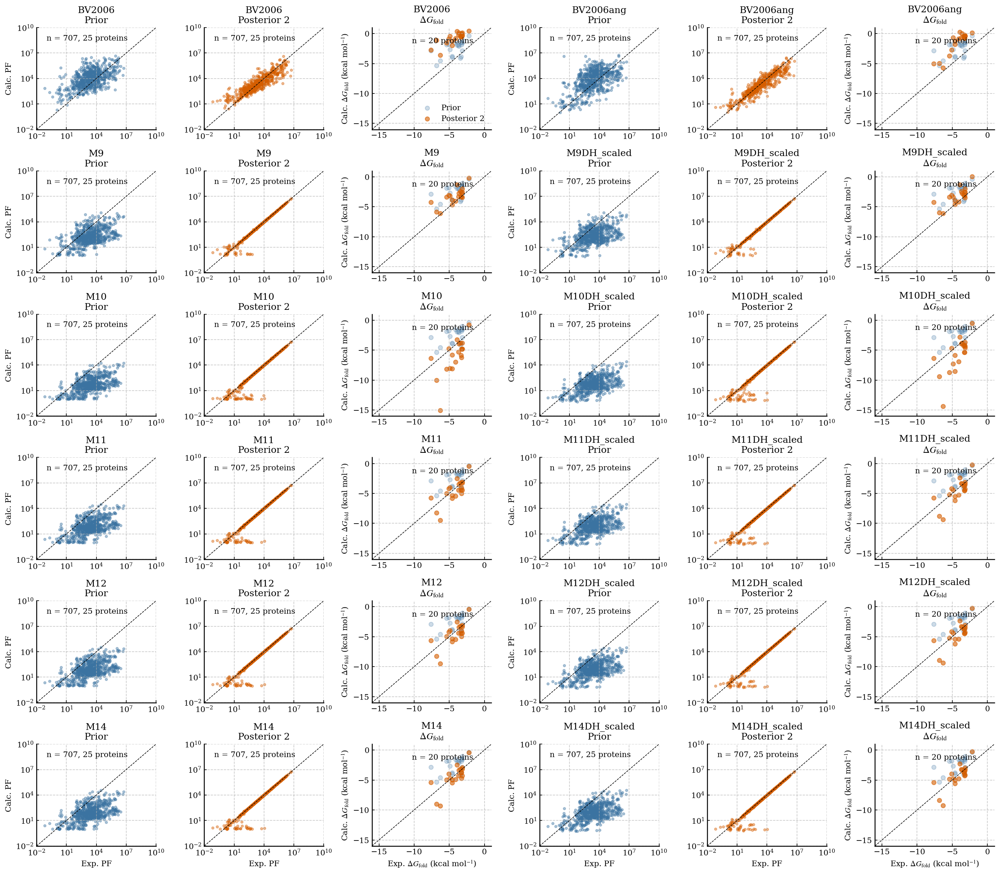

In [16]:
models = ['rewBV2006', 'rewBV2006ang',
          'rewM9', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH_scaled',
          'rewM11', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH_scaled',
          'rewM14', 'rewM14DH_scaled']
model_labels = [m[3:] for m in models]

proteins = ['ACBP', 'ACP', 'alpha3D', 'CLN025', 'GB3', 'HP36', 'Im7', 'NuG2', 'Ubiquitin',
            'EEHEE_rd4_0642-6xHis', 'EEHEE_rd4_0642-No-His',
            'EEHEE_rd4_0871-6xHis', 'EEHEE_rd4_0871-No-His',
            'EEHEE_rd4_0871_K31L_E36V-No-His', 'EHEE_rd2_0005-6xHis',
            'HEEH_rd4_0097-6xHis', 'HHH_rd1_0012-6xHis', 'HHH_rd3_0062-6xHis',
            'HHH_rd4_0518-6xHis', 'HHH_rd4_0518-No-His',
            'HHH_rd4_0518_R35D_G45L-No-His', 'HHH_rd4_0557-6xHis',
            'LysM_0873-No-His', 'LysM_1380-No-His', 'LysM_3314-No-His']

PRIOR_COLOR = "#3B73A1"
POSTERIOR_COLOR = "#D55E00"

# --------------------------------------------------
# Experimental dG
# --------------------------------------------------
exp_dG_all = []
for protein in proteins:
    if os.path.exists(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat'):
        exp_dG_all.append(np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat')[0])
    else:
        exp_dG_all.append(np.nan)
exp_dG_all = np.array(exp_dG_all)

# --------------------------------------------------
# Experimental PFs
# --------------------------------------------------
all_expPF = []
for protein in proteins:
    exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name='rewBV2006')
    expPF = np.array(exp["PF"][idxs])
    all_expPF.append(expPF)
all_expPF = np.concatenate([x for x in all_expPF if len(x) > 0])

# --------------------------------------------------
# Figure
# --------------------------------------------------
ncols = 6  # 2 models per row, 3 columns (PF prior, PF post, dG) each
nrows = int(np.ceil(len(models) / 2))  # 6 for 12 models
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols * 0.75, 3.5 * nrows * 0.75))
identity_pf = np.logspace(-2, 10, 200)
identity_dG = np.linspace(-17, 2, 200)

for i, (model, model_label) in enumerate(zip(models, model_labels)):
    row = i // 2
    col_offset = (i % 2) * 3

    data = np.load(f'{model}_data_dict.npy', allow_pickle=True).item()
    all_calcPF_prior = np.concatenate([x for x in data['prior PF'] if len(x) > 0])
    all_calcPF_post = np.concatenate([x for x in data['rew PF'] if len(x) > 0])
    dGpcalc_prior = np.array(data['dGp prior'])
    dGpcalc_post = np.array(data['dGp post'])

    # --------------------------------------------------
    # Column 1: PF prior
    # --------------------------------------------------
    ax = axes[row, col_offset + 0]

    exp_log_pf = np.log10(all_expPF)
    calc_log_pf = np.log10(all_calcPF_prior)
    r = scipy.stats.pearsonr(exp_log_pf, calc_log_pf)[0]
    rmse = RMSE(exp_log_pf, calc_log_pf)
    ccc = calc_ccc(exp_log_pf, calc_log_pf)

    ax.scatter(all_expPF, all_calcPF_prior, color=PRIOR_COLOR, alpha=0.4, s=9, rasterized=True)
    ax.plot(identity_pf, identity_pf, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(1e-2, 1e10); ax.set_ylim(1e-2, 1e10)

    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    ax.set_title(f"{model_label}\nPrior")
    #ax.text(1e-1, 1e9, rf"RMSE = {rmse:.2f}, $r$ = {r:.2f}, $\rho_c$ = {ccc:.2f}")
    ax.text(1e-1, 10**8.5, f"n = {len(all_expPF)}, {len(np.unique(proteins))} proteins")

    ax.set_ylabel("Calc. PF")
    if row == nrows - 1:
        ax.set_xlabel("Exp. PF")

    # --------------------------------------------------
    # Column 2: PF posterior
    # --------------------------------------------------
    ax = axes[row, col_offset + 1]

    calc_log_pf = np.log10(all_calcPF_post)
    r = scipy.stats.pearsonr(exp_log_pf, calc_log_pf)[0]
    rmse = RMSE(exp_log_pf, calc_log_pf)
    ccc = calc_ccc(exp_log_pf, calc_log_pf)

    ax.scatter(all_expPF, all_calcPF_post, color=POSTERIOR_COLOR, alpha=0.4, s=9, rasterized=True)
    ax.plot(identity_pf, identity_pf, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(1e-2, 1e10); ax.set_ylim(1e-2, 1e10)

    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    ax.set_title(f"{model_label}\nPosterior 2")
    #ax.text(1e-1, 1e9, rf"RMSE = {rmse:.2f}, $r$ = {r:.2f}, $\rho_c$ = {ccc:.2f}")
    ax.text(1e-1, 10**8.5, f"n = {len(all_expPF)}, {len(np.unique(proteins))} proteins")

    if row == nrows - 1:
        ax.set_xlabel("Exp. PF")

    # --------------------------------------------------
    # Column 3: dG prior + posterior
    # --------------------------------------------------
    ax = axes[row, col_offset + 2]

    valid = ~np.isnan(exp_dG_all)
    exp_dG = exp_dG_all[valid]
    calc_dG_prior = dGpcalc_prior[valid]
    calc_dG_post = dGpcalc_post[valid]

    r_prior = scipy.stats.pearsonr(exp_dG, calc_dG_prior)[0]
    rmse_prior = RMSE(exp_dG, calc_dG_prior)
    ccc_prior = calc_ccc(exp_dG, calc_dG_prior)

    r_post = scipy.stats.pearsonr(exp_dG, calc_dG_post)[0]
    rmse_post = RMSE(exp_dG, calc_dG_post)
    ccc_post = calc_ccc(exp_dG, calc_dG_post)

    ax.scatter(exp_dG, calc_dG_prior, color=PRIOR_COLOR, alpha=0.25, s=30, rasterized=True, label='Prior')
    ax.scatter(exp_dG, calc_dG_post, color=POSTERIOR_COLOR, alpha=0.60, s=30, rasterized=True, label='Posterior 2')
    ax.plot(identity_dG, identity_dG, color='black', linestyle='dashed', linewidth=0.75)

    ax.set_xlim(-16, 1); ax.set_ylim(-16, 1)

    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both', which='both', top=False, right=False)

    ax.set_title(f"{model_label}\n$\Delta G_{{\\mathrm{{fold}}}}$")
    #ax.text(-10.3, 0.0, rf"Prior: RMSE = {rmse_prior:.2f}, $r$ = {r_prior:.2f}, $\rho_c$ = {ccc_prior:.2f}", color=PRIOR_COLOR)
    #ax.text(-10.3, -0.8, rf"Posterior 2: RMSE = {rmse_post:.2f}, $r$ = {r_post:.2f}, $\rho_c$ = {ccc_post:.2f}", color=POSTERIOR_COLOR)
    ax.text(-10.3, -1.6, f"n = {len(exp_dG)} proteins")

    ax.set_ylabel(r'Calc. $\Delta G_{\mathrm{fold}}$ (kcal mol$^{-1}$)')
    if row == nrows - 1:
        ax.set_xlabel(r'Exp. $\Delta G_{\mathrm{fold}}$ (kcal mol$^{-1}$)')

    if row == 0 and col_offset == 0:
        ax.legend(frameon=False, loc='lower right')

plt.tight_layout()
plt.savefig('pdf_plots/HDX_dG_all_models_prior_posterior_largerlims_dG.pdf', dpi=300, bbox_inches='tight')
plt.show()